# Proyecto de Machine Learning — Spotify Tracks Dataset

**MLY1101 — Machine Learning | Proyecto semestral**

**Caso C**: Inteligencia musical y predicción de popularidad de canciones

Este notebook conserva las fases 1 a 3 de CRISP-DM desarrolladas en la Evaluación Parcial N°1 (comprensión del negocio, comprensión de los datos y preparación de los datos), ahora organizadas como base reproducible para continuar con modelamiento y evaluación en la Evaluación Parcial N°2.

**Contexto del proyecto:** las plataformas de streaming y otros actores de la industria musical necesitan contar con criterios basados en datos para apoyar decisiones de promoción y priorización de canciones. El proyecto estudia qué información puede obtenerse de las características disponibles en Spotify para comprender y estimar su nivel de popularidad. La etapa de modelamiento combinará aprendizaje supervisado para estimar `popularity` y aprendizaje no supervisado para identificar perfiles musicales dentro del catálogo.


In [1]:
# Configuración portable del proyecto: Colab + PC/GitHub

import sys
import subprocess
import json
import platform
from pathlib import Path
from urllib.request import urlretrieve

# kneed no siempre viene instalado en Google Colab.
# En un PC se recomienda instalar primero requirements.txt.
try:
    import kneed
    from kneed import KneeLocator
except ImportError:
    print("kneed no está instalado. Instalando kneed==0.8.6...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "kneed==0.8.6"
    ])
    import kneed
    from kneed import KneeLocator

# Librerías
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

# Supervisado
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# No supervisado
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Preparación y validación
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# ---------------------------------------------------------
# 1. Detectar la raíz del proyecto
# ---------------------------------------------------------

def encontrar_raiz_proyecto():
    """
    Busca hacia arriba una carpeta que parezca ser la raíz del proyecto.

    En un repositorio local se reconoce por:
    - la carpeta .git, o
    - README.md junto con la carpeta notebooks.

    Si no se encuentra, se usa el directorio actual.
    Esto permite que el mismo notebook funcione también en Colab.
    """
    actual = Path.cwd().resolve()

    for carpeta in [actual, *actual.parents]:
        if (carpeta / ".git").exists():
            return carpeta

        if (
            (carpeta / "README.md").exists()
            and (carpeta / "notebooks").exists()
        ):
            return carpeta

    return actual


PROJECT_ROOT = encontrar_raiz_proyecto()

DATA_DIR = PROJECT_ROOT / "data"
IMAGES_DIR = PROJECT_ROOT / "images"
MODELS_DIR = PROJECT_ROOT / "models"

for carpeta in (DATA_DIR, IMAGES_DIR, MODELS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------
# 2. Dataset
# ---------------------------------------------------------

DATA_PATH = DATA_DIR / "Spotify_Tracks_Dataset.csv"

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "monkIIlol/spotify_track_dataset/main/data/"
    "Spotify_Tracks_Dataset.csv"
)

# Si el dataset ya está incluido en el proyecto, se utiliza directamente.
# Si falta (por ejemplo, al abrir solo el notebook en Colab), se descarga.
if not DATA_PATH.exists():
    print("Dataset no encontrado. Descargando Spotify_Tracks_Dataset.csv...")
    try:
        urlretrieve(DATA_URL, DATA_PATH)
    except Exception as exc:
        raise RuntimeError(
            "No fue posible descargar el dataset. "
            "Comprueba la conexión a Internet o coloca "
            "'Spotify_Tracks_Dataset.csv' dentro de la carpeta data/."
        ) from exc

print("Raíz del proyecto:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("Imágenes:", IMAGES_DIR)
print("Modelos:", MODELS_DIR)


# ---------------------------------------------------------
# 3. Reproducibilidad
# ---------------------------------------------------------

RANDOM_STATE = 29

print("\nVersiones del entorno:")
print("Python:", platform.python_version())
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("joblib:", joblib.__version__)
print("kneed:", getattr(kneed, "__version__", "no informada"))


kneed no está instalado. Instalando kneed==0.8.6...
Raíz del proyecto: D:\DUOC\Machine_Learning\Spotify_ML_portable
Dataset: D:\DUOC\Machine_Learning\Spotify_ML_portable\data\Spotify_Tracks_Dataset.csv
Imágenes: D:\DUOC\Machine_Learning\Spotify_ML_portable\images
Modelos: D:\DUOC\Machine_Learning\Spotify_ML_portable\models

Versiones del entorno:
Python: 3.12.6
numpy: 2.1.1
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.9.2
seaborn: 0.13.2
joblib: 1.4.2
kneed: 0.8.6


## 1. Primera impresión de los datos


In [2]:
# Carga del CSV original. BD_raw se conserva sin modificaciones como copia de referencia.
BD_raw = pd.read_csv(DATA_PATH)
BD_raw.head(3)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


In [3]:
# Dimensiones originales del archivo
print(BD_raw.shape)


(114000, 21)


El dataset cuenta con 114000 registros y 21 columnas en el archivo CSV. Una de ellas (`Unnamed: 0`) corresponde a un índice exportado y no representa una variable informativa del problema.


## 2. Comprensión de los datos
Primer perfil general: dimensiones y tipos de cada columna.


In [4]:
# Estructura, tipos de datos y valores no nulos de la base original
BD_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

Se aprecian solamente 3 nulos en `artists`, `album_name` y `track_name` (1 por cada columna), posiblemente pertenezcan al mismo registro.

Esto queda pendiente para los apartados posteriores dirigidos al diagnóstico de calidad de los datos.


---
### Descripción de las columnas

#### 1. Identificación de la canción

* **`track_id`**
  Identificador de la pista en Spotify. Un mismo `track_id` puede aparecer en varias filas del dataset cuando la pista está asociada a más de un género.

* **`track_name`**
  Nombre de la canción.

* **`artists`**
  Artistas que interpretan la canción. Cuando participa más de uno, sus nombres aparecen separados por `;`.

* **`album_name`**
  Álbum en el que aparece la canción.

* **`track_genre`**
  Género asignado a la canción.

---

#### 2. Información general

* **`popularity`**
  Popularidad de la canción en una escala de **0 a 100**, donde 100 representa la mayor popularidad.

  El valor depende principalmente de:

  * La cantidad total de reproducciones.
  * Qué tan recientes son esas reproducciones.

  Una misma canción puede recibir puntuaciones diferentes si aparece, por ejemplo, como sencillo y como parte de un álbum.

* **`duration_ms`**
  Duración de la canción expresada en milisegundos.

* **`explicit`**
  Indica si la canción contiene letras explícitas:

  * `true`: contiene letras explícitas.
  * `false`: no contiene letras explícitas o se desconoce.

---

#### 3. Características perceptuales del audio

Estas variables se expresan principalmente en una escala de **0,0 a 1,0**.

* **`danceability`**
  Indica qué tan adecuada es la canción para bailar. Considera elementos como el tempo, la estabilidad del ritmo, la fuerza del pulso y la regularidad general.

  * `0,0`: poco bailable.
  * `1,0`: muy bailable.

* **`energy`**
  Representa la intensidad y actividad percibidas. Las canciones rápidas, fuertes o ruidosas suelen presentar valores más altos.

  * `0,0`: baja energía.
  * `1,0`: alta energía.

* **`speechiness`**
  Detecta la presencia de palabras habladas.

  * Menor que `0,33`: principalmente música.
  * Entre `0,33` y `0,66`: combinación de música y habla.
  * Mayor que `0,66`: predominio de contenido hablado.

* **`acousticness`**
  Nivel de confianza de que la canción sea acústica.

  * `0,0`: baja confianza.
  * `1,0`: alta confianza.

* **`instrumentalness`**
  Estima la probabilidad de que la canción no contenga voces. Los sonidos como «ooh» y «aah» se consideran instrumentales, mientras que el rap y las palabras habladas se consideran vocales.

  Los valores cercanos a `1,0` indican una mayor probabilidad de que sea instrumental.

* **`liveness`**
  Estima la presencia de público en la grabación. Los valores superiores a `0,8` indican una alta probabilidad de que haya sido grabada en vivo.

* **`valence`**
  Describe la positividad musical transmitida por la canción.

  * Valores altos: sonido alegre, animado o eufórico.
  * Valores bajos: sonido triste, deprimido o enojado.

* **`loudness`**
  Volumen sonoro general de la canción, medido en decibelios (`dB`).

---

#### 4. Características musicales

* **`key`**
  Tonalidad principal de la canción. Los números representan notas musicales:

  * `0`: Do
  * `1`: Do♯/Re♭
  * `2`: Re
  * Continúa sucesivamente hasta `11`.
  * `-1`: no se detectó una tonalidad.

* **`mode`**
  Indica el modo musical:

  * `1`: modo mayor.
  * `0`: modo menor.

* **`tempo`**
  Velocidad estimada de la canción, medida en pulsaciones por minuto (`BPM`).

* **`time_signature`**
  Compás estimado de la canción. Indica cuántos pulsos contiene cada compás o medida. Sus valores van desde `3` hasta `7`, correspondientes a compases como `3/4` y `7/4`.

---


## 3. Diagnóstico de calidad de datos


### 3.1 Valores faltantes
Retomamos lo que quedó pendiente en la sección 2.


In [5]:
# Revisar únicamente las columnas que contienen valores faltantes
nulos = BD_raw.isnull().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0])


Valores nulos por columna:
artists       1
album_name    1
track_name    1
dtype: int64


Confirmamos que hay 3 nulos en `artists`, `album_name` y `track_name` (1 por cada columna), queda pendiente descubrir qué ocurrió con ese registro.


### 3.2 Registros duplicados


Primero se revisan duplicados de contenido. La columna `Unnamed: 0` se excluye de la comparación porque corresponde a un índice exportado y puede hacer que dos registros idénticos parezcan diferentes.


In [6]:
# Detectar duplicados reales sin considerar el índice exportado
columnas_contenido = [col for col in BD_raw.columns if col != "Unnamed: 0"]
mask_duplicado_exacto = BD_raw.duplicated(
    subset=columnas_contenido,
    keep="first"
)

print("Duplicados reales encontrados:", mask_duplicado_exacto.sum())


Duplicados reales encontrados: 450


**Hallazgo:** al excluir `Unnamed: 0` del criterio de comparación se identifican **450 registros completamente duplicados**. Estos registros no aportan información adicional y serán eliminados durante la limpieza.


`track_id` se repite miles de veces en el dataset. Antes de eliminar nada hay que entender **por qué**.


In [7]:
# Analizar la repetición de track_id sin contar los duplicados exactos ya identificados
track_id_sin_duplicados = BD_raw.loc[~mask_duplicado_exacto, "track_id"]
filas_extra_track = track_id_sin_duplicados.duplicated().sum()

print("Filas adicionales por repetición de track_id:", filas_extra_track)

# Mostrar un ejemplo representativo de una pista asociada a varios géneros
ejemplo_id = track_id_sin_duplicados.value_counts().index[0]
columnas_ejemplo = ["track_name", "artists", "track_genre"]

print()
print("Ejemplo de una canción repetida en varios géneros:")
print(
    BD_raw.loc[
        (~mask_duplicado_exacto) & (BD_raw["track_id"] == ejemplo_id),
        columnas_ejemplo
    ]
)


Filas adicionales por repetición de track_id: 23809

Ejemplo de una canción repetida en varios géneros:
                         track_name    artists        track_genre
8315    Baby Blue - Remastered 2010  Badfinger              blues
19759   Baby Blue - Remastered 2010  Badfinger            country
34728   Baby Blue - Remastered 2010  Badfinger               folk
62226   Baby Blue - Remastered 2010  Badfinger              j-pop
63087   Baby Blue - Remastered 2010  Badfinger             j-rock
82064   Baby Blue - Remastered 2010  Badfinger          power-pop
84129   Baby Blue - Remastered 2010  Badfinger         psych-rock
99727   Baby Blue - Remastered 2010  Badfinger  singer-songwriter
102732  Baby Blue - Remastered 2010  Badfinger         songwriter


**Hallazgo:** no es un error de captura. La misma canción está etiquetada en varios géneros musicales a la vez (en el ejemplo de arriba, el mismo tema aparece repetido bajo distintos `track_genre`). Por lo tanto, **no corresponde eliminar estas repeticiones como si fueran duplicados exactos**, porque se perdería información real de multi-género.

Esta estructura se conservará durante la limpieza y se resolverá posteriormente definiendo la unidad de análisis adecuada para cada uso.


### 3.3 Consistencia de `popularity` en `track_id` repetidos


In [8]:
# Resumir la variación de popularity entre las apariciones de un mismo track_id
resumen_popularity_track = (
    BD_raw.loc[~mask_duplicado_exacto]
    .groupby("track_id")["popularity"]
    .agg(
        popularity_min="min",
        popularity_max="max",
        popularity_nunique="nunique"
    )
)

resumen_popularity_track["popularity_range"] = (
    resumen_popularity_track["popularity_max"]
    - resumen_popularity_track["popularity_min"]
)

tracks_popularity_variable = resumen_popularity_track[
    resumen_popularity_track["popularity_nunique"] > 1
]

print(
    "Track IDs con más de un valor de popularity:",
    tracks_popularity_variable.shape[0]
)
print(
    "De ellos, con una diferencia máxima de 1 punto:",
    (tracks_popularity_variable["popularity_range"] == 1).sum()
)
print(
    "Con una diferencia mayor a 5 puntos:",
    (tracks_popularity_variable["popularity_range"] > 5).sum()
)
print(
    "Mayor diferencia observada:",
    tracks_popularity_variable["popularity_range"].max()
)


Track IDs con más de un valor de popularity: 720
De ellos, con una diferencia máxima de 1 punto: 673
Con una diferencia mayor a 5 puntos: 17
Mayor diferencia observada: 44


**Hallazgo:** existen **720 `track_id`** con más de un valor observado de `popularity`. En **673** de ellos la diferencia máxima es de solo 1 punto, aunque existen algunos casos con variaciones mayores. Como el dataset no incluye una marca temporal que permita ordenar esas observaciones, no es posible seleccionar de forma fundamentada cuál debería considerarse la medición definitiva.

Estas diferencias no se tratarán como duplicados ni como errores automáticos. Antes de analizar o modelar a nivel de canción, las observaciones de `popularity` deberán consolidarse de forma explícita y trazable.


### 3.4 Outliers evidentes: duración de la canción


In [9]:
# Revisar duraciones imposibles o evidentemente anómalas antes de transformar la variable
duracion_cero = BD_raw["duration_ms"].eq(0)

print("Canciones con duración cero =", duracion_cero.sum())
print(
    BD_raw.loc[
        duracion_cero,
        ["track_name", "artists", "track_genre", "duration_ms"]
    ]
)


Canciones con duración cero = 1
      track_name artists track_genre  duration_ms
65900        NaN     NaN       k-pop            0


**Hallazgo:** en el punto 3.1 vimos los valores nulos del dataset y ahora comprobamos que pertenecen a la misma fila que presenta `duration_ms = 0`: un único registro corrupto en el origen de los datos.


## 4. Limpieza y transformación de datos

La limpieza parte siempre desde `BD_raw` y genera una nueva base `BD_limpia`. La base original no se modifica.

Se eliminan:
- `Unnamed: 0`, porque corresponde a un índice exportado.
- Los 450 duplicados exactos detectados en el diagnóstico.
- El único registro corrupto con datos identificadores faltantes y duración igual a cero.

Además, durante esta etapa se normalizan dos valores especiales antes de construir la unidad de análisis:

- `tempo = 0` se representa como valor faltante (`NaN`) en lugar de eliminar la canción. En este proyecto se interpreta como ausencia de una medición de tempo utilizable.
- `time_signature = 0` se representa como categoría `Unknown`, evitando tratar el cero como un compás musical válido.

Estas decisiones modifican la representación del dato, pero no estiman valores a partir del conjunto completo ni utilizan información de `popularity`.


In [10]:
# Crear la base limpia desde la fuente original sin modificar BD_raw
BD_limpia = (
    BD_raw.loc[~mask_duplicado_exacto]
    .drop(columns="Unnamed: 0")
    .dropna(subset=["artists", "album_name", "track_name"])
    .copy()
)

print(f"Filas originales: {BD_raw.shape[0]}")
print(f"Filas después de limpieza básica: {BD_limpia.shape[0]}")
print(f"Duraciones iguales a cero: {(BD_limpia['duration_ms'] == 0).sum()}")


Filas originales: 114000
Filas después de limpieza básica: 113549
Duraciones iguales a cero: 0


Agregaremos características simples para mejorar interpretabilidad y análisis:

- `duration_ms` → `duration_min`: convertido a minutos.
- `mode` → `mode_name`: map mode (0/1) → Minor/Major.
- `key` → `key_name`: map key (0,1,2,...10,11) → C, C#/Db, D, ..., A#/Bb, B.
- `tempo = 0` → valor faltante (`NaN`).
- `time_signature = 0` → categoría `Unknown`.

Después de crear las nuevas representaciones se eliminan las columnas originales que fueron reemplazadas (`duration_ms`, `mode` y `key`).


In [11]:
# Crear variables interpretables a partir de las columnas originales
BD_limpia["duration_min"] = BD_limpia["duration_ms"] / 60000
BD_limpia["mode_name"] = BD_limpia["mode"].map({1: "Major", 0: "Minor"})

key_map = {
    0: "C", 1: "C#/Db", 2: "D", 3: "D#/Eb",
    4: "E", 5: "F", 6: "F#/Gb", 7: "G",
    8: "G#/Ab", 9: "A", 10: "A#/Bb", 11: "B",
    -1: "Unknown"
}
BD_limpia["key_name"] = BD_limpia["key"].map(key_map)

# Normalizar valores especiales sin eliminar pistas
BD_limpia["tempo"] = BD_limpia["tempo"].replace(0, np.nan)
BD_limpia["time_signature"] = (
    BD_limpia["time_signature"]
    .replace(0, "Unknown")
    .astype(str)
)

# Retirar las columnas que ya tienen una representación más interpretable
BD_limpia = BD_limpia.drop(columns=["duration_ms", "mode", "key"])

print("Dimensiones de BD_limpia:", BD_limpia.shape)
print("Valores faltantes de tempo:", BD_limpia["tempo"].isna().sum())
print(
    "Compases Unknown:",
    (BD_limpia["time_signature"] == "Unknown").sum()
)
print(
    BD_limpia[
        ["duration_min", "mode_name", "key_name", "tempo", "time_signature"]
    ].head(3)
)


Dimensiones de BD_limpia: (113549, 20)
Valores faltantes de tempo: 157
Compases Unknown: 163
   duration_min mode_name key_name   tempo time_signature
0      3.844433     Minor    C#/Db  87.917              4
1      2.493500     Major    C#/Db  77.489              4
2      3.513767     Major        C  76.332              4


## 5. Estructuración del dataset y preparación para modelamiento


`BD_limpia` conserva la estructura válida del dataset: una misma pista puede aparecer en varias filas por pertenecer a más de un género. Para los análisis donde **una observación debe representar una canción**, se construye una base consolidada por `track_id`.

Antes de consolidar se comprueba que las características estables de una pista no cambien entre sus distintas apariciones. `track_genre` se conserva como relación multi-género y `popularity` se resume mediante la **mediana**, porque evita favorecer sistemáticamente valores máximos o mínimos y reduce el efecto de observaciones extremas. También se conservan mínimo, máximo y rango para no ocultar la variabilidad observada.

En 89.020 pistas `popularity` ya tiene un único valor; la regla de consolidación solo interviene en los 720 `track_id` con más de una observación del target.


In [12]:
# Verificar que las características propias de una pista sean consistentes entre filas
columnas_estables = [
    "artists", "album_name", "track_name", "explicit",
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "time_signature", "duration_min", "mode_name", "key_name"
]

variacion_estable = (
    BD_limpia
    .groupby("track_id")[columnas_estables]
    .nunique(dropna=False)
)

tracks_inconsistentes = (variacion_estable > 1).any(axis=1).sum()

print(
    "Track IDs con inconsistencias en características estables:",
    tracks_inconsistentes
)


Track IDs con inconsistencias en características estables: 0


In [13]:
# 1) Información estable: una fila representativa por track_id
BD_base_canciones = (
    BD_limpia[["track_id"] + columnas_estables]
    .drop_duplicates(subset="track_id")
    .copy()
)

# 2) Géneros: conservar todas las categorías asociadas a cada pista
generos_por_track = (
    BD_limpia
    .groupby("track_id")["track_genre"]
    .agg(lambda valores: sorted(set(valores)))
    .reset_index(name="track_genres")
)
generos_por_track["n_genres"] = generos_por_track["track_genres"].apply(len)

# 3) Popularidad: obtener un valor representativo sin ocultar la variación observada
popularidad_por_track = (
    BD_limpia
    .groupby("track_id")["popularity"]
    .agg(
        popularity="median",
        popularity_min="min",
        popularity_max="max",
        popularity_nunique="nunique"
    )
    .reset_index()
)
popularidad_por_track["popularity_range"] = (
    popularidad_por_track["popularity_max"]
    - popularidad_por_track["popularity_min"]
)

# 4) Base analítica: una fila equivale a una pista de Spotify
BD_canciones = (
    BD_base_canciones
    .merge(generos_por_track, on="track_id", how="left")
    .merge(popularidad_por_track, on="track_id", how="left")
)

print("Filas de BD_canciones:", BD_canciones.shape[0])
print("Track IDs únicos:", BD_canciones["track_id"].nunique())
print(
    "Tracks con múltiples valores de popularity:",
    (BD_canciones["popularity_nunique"] > 1).sum()
)


Filas de BD_canciones: 89740
Track IDs únicos: 89740
Tracks con múltiples valores de popularity: 720


Para análisis por género se necesita conservar la relación muchos-a-muchos entre canciones y categorías. Por ello se crea `BD_generos`, donde una fila representa una relación `track_id`–`track_genre`, pero utilizando la popularidad consolidada de cada canción.


In [14]:
# Vista específica para análisis por género: una fila por relación canción-género
BD_generos = (
    BD_limpia[["track_id", "track_genre"]]
    .drop_duplicates()
    .merge(
        BD_canciones[["track_id", "popularity"]],
        on="track_id",
        how="left"
    )
)

print("Relaciones canción-género:", BD_generos.shape[0])
print(
    "Relaciones duplicadas:",
    BD_generos.duplicated(["track_id", "track_genre"]).sum()
)


Relaciones canción-género: 113549
Relaciones duplicadas: 0


### Flujo de bases resultantes

- `BD_raw`: 114.000 filas. Fuente original sin modificaciones.
- `BD_limpia`: 113.549 filas. Registros válidos de la estructura canción-género.
- `BD_canciones`: 89.740 filas. Una fila representa una pista única; es la base analítica principal.
- `BD_generos`: 113.549 filas. Vista específica para análisis donde importa la pertenencia a género.

La base destinada a Machine Learning se construirá posteriormente como `BD_modelo`, seleccionando desde `BD_canciones` únicamente las variables necesarias. `BD_canciones` no se modificará para ese propósito.


### 5.1 Estrategia de preparación para modelamiento

La limpieza general y la representación de los datos quedan resueltas antes del modelamiento. También se define en esta etapa la estrategia de transformación que necesitarán posteriormente los algoritmos:

- Los valores faltantes de `tempo` se imputarán mediante la **mediana**.
- Las variables continuas se **estandarizarán cuando el algoritmo lo requiera**.
- `mode_name`, `key_name` y `time_signature` se representarán mediante **One-Hot Encoding**, es decir, una columna binaria por categoría.
- `track_genres` se transformará en columnas binarias por género, permitiendo que una misma canción pertenezca a varios géneros.
- `explicit` se conservará como variable binaria.

Estas decisiones pertenecen a **Preparación de los Datos** dentro de CRISP-DM. Sin embargo, las estadísticas y categorías necesarias para ejecutar las transformaciones no se calculan sobre el dataset completo.

En aprendizaje supervisado, la imputación, el escalamiento y la codificación se **ajustarán únicamente con los datos de entrenamiento** —y dentro de cada partición de validación cuando corresponda— para evitar fuga de información, es decir, impedir que el conjunto de prueba influya en el entrenamiento.

La implementación se realizará mediante `Pipeline` de scikit-learn, que permite aplicar en el mismo orden la preparación y el modelo tanto en entrenamiento como en prueba.

En aprendizaje no supervisado, las transformaciones requeridas por K-Means se aplicarán sobre el conjunto utilizado para el análisis de clustering, ya que en ese flujo no existe una variable objetivo supervisada ni una partición train/test destinada a estimar error de predicción.

## 6. Análisis univariado: distribución de la variable objetivo (`popularity`)


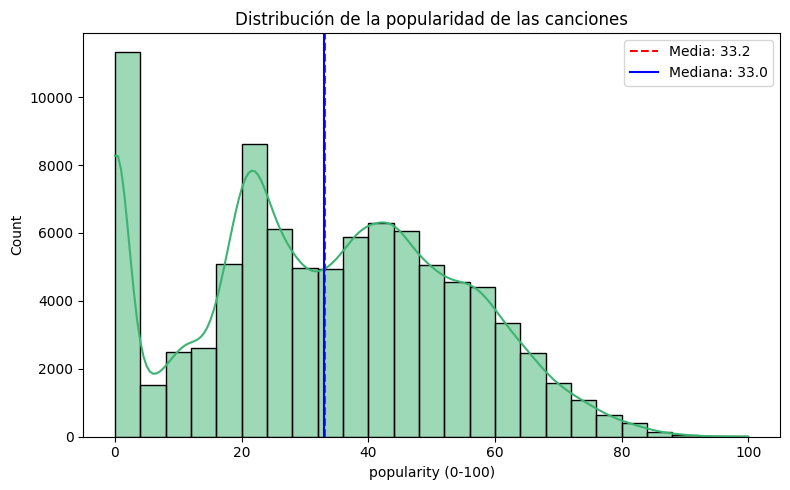

Media: 33.20
Mediana: 33.00
Sesgo (skew): 0.07


In [15]:
# Analizar popularity a nivel de pista única para evitar ponderar varias veces canciones multigénero
plt.figure(figsize=(8, 5))
sns.histplot(
    data=BD_canciones,
    x="popularity",
    kde=True,
    color="mediumseagreen",
    bins=25
)

media_pop = BD_canciones["popularity"].mean()
mediana_pop = BD_canciones["popularity"].median()

plt.axvline(
    media_pop,
    color="red",
    linestyle="--",
    label=f"Media: {media_pop:.1f}"
)
plt.axvline(
    mediana_pop,
    color="blue",
    linestyle="-",
    label=f"Mediana: {mediana_pop:.1f}"
)

plt.title("Distribución de la popularidad de las canciones")
plt.xlabel("popularity (0-100)")
plt.legend()
plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "01_distribucion_popularity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Media: {media_pop:.2f}")
print(f"Mediana: {mediana_pop:.2f}")
print(f"Sesgo (skew): {BD_canciones['popularity'].skew():.2f}")


**Hallazgo:** el sesgo (skew) es prácticamente 0, por lo que la distribución general sigue siendo bastante simétrica. Al trabajar a nivel de pista única, la media es aproximadamente 33.2 y la mediana 33.0.

La consolidación por `track_id` evita que una canción asociada a varios géneros tenga más peso que otra dentro de esta distribución.


### 6.1 Anomalía a evaluar: popularity = 0


In [16]:
# Cuantificar los valores cero sobre canciones únicas
canciones_popularity_cero = BD_canciones[
    BD_canciones["popularity"] == 0
]

porcentaje_cero = (
    canciones_popularity_cero.shape[0]
    / BD_canciones.shape[0]
    * 100
)

print(
    f"Canciones con popularity = 0: "
    f"{canciones_popularity_cero.shape[0]} "
    f"({porcentaje_cero:.1f}% del total)"
)


Canciones con popularity = 0: 9393 (10.5% del total)


Los valores `popularity = 0` se conservan. No existe evidencia suficiente para tratarlos como errores: pueden corresponder a pistas genuinamente poco escuchadas o a la naturaleza temporal de la métrica de Spotify.

Al medir sobre `track_id` únicos, representan aproximadamente el **10,5% de las canciones**, por lo que el 14,1% observado inicialmente debe interpretarse como proporción de filas de la estructura canción-género, no como proporción de canciones únicas.


### 6.2 Relación entre `popularity = 0` y canciones presentes en varios géneros

Se mantiene el hallazgo detectado en la primera exploración, pero ahora se evalúa a nivel de pista única. Una canción se considera repetida en la estructura original cuando su `track_id` quedó asociado a más de un género (`n_genres > 1`).


In [17]:
# Comparar la frecuencia de popularity = 0 según la multiplicidad de géneros de cada pista
track_multigenero = BD_canciones["n_genres"] > 1

pct_cero_repetidos = (
    BD_canciones.loc[track_multigenero, "popularity"]
    .eq(0)
    .mean() * 100
)

pct_cero_unicos = (
    BD_canciones.loc[~track_multigenero, "popularity"]
    .eq(0)
    .mean() * 100
)

print(
    f"Popularity = 0 en canciones presentes en varios géneros: "
    f"{pct_cero_repetidos:.1f}%"
)
print(
    f"Popularity = 0 en canciones presentes en un solo género: "
    f"{pct_cero_unicos:.1f}%"
)


Popularity = 0 en canciones presentes en varios géneros: 22.2%
Popularity = 0 en canciones presentes en un solo género: 7.9%


**Hallazgo:** `popularity = 0` continúa siendo mucho más frecuente entre canciones que aparecían en varias filas del dataset por pertenecer a varios géneros. La asociación, por tanto, no desaparece al corregir la unidad de análisis.

Sin embargo, esta relación por sí sola no permite afirmar que dichos valores sean errores o ruido de captura.


## 7. Duración de las canciones (regla IQR)


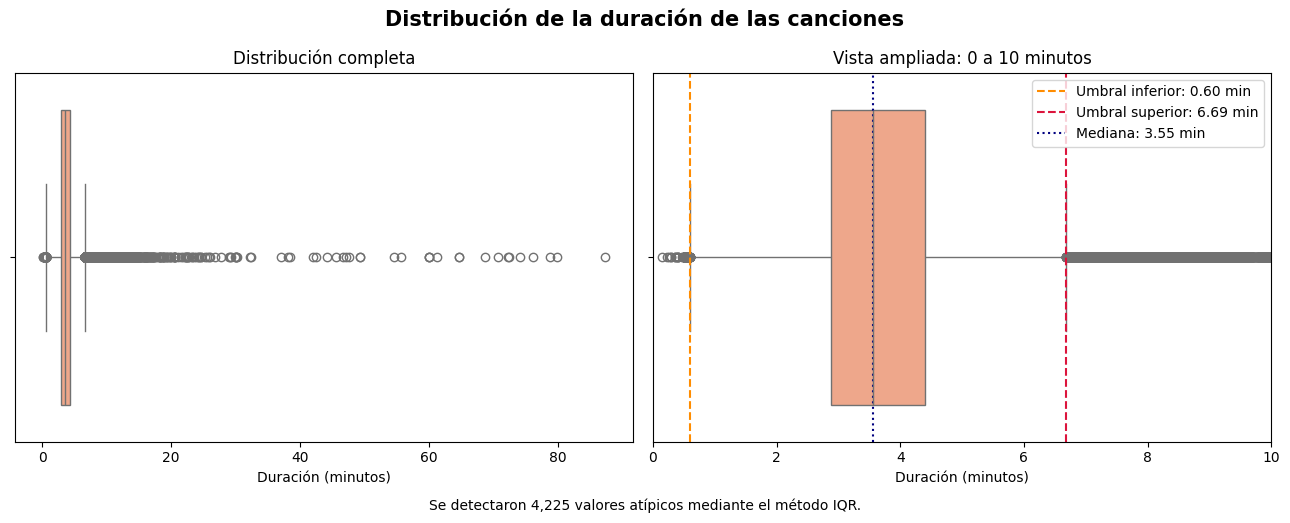

In [18]:
# Calcular límites IQR sobre pistas únicas
duration_min = BD_canciones["duration_min"]

Q1 = duration_min.quantile(0.25)
mediana = duration_min.median()
Q3 = duration_min.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

mask_outlier = (
    (duration_min < limite_inferior)
    | (duration_min > limite_superior)
)
outliers = BD_canciones.loc[mask_outlier]

# Visualizar la distribución completa y una ampliación del rango habitual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(x=duration_min, ax=axes[0], color="lightsalmon")
axes[0].set_title("Distribución completa")
axes[0].set_xlabel("Duración (minutos)")

sns.boxplot(x=duration_min, ax=axes[1], color="lightsalmon")
axes[1].set_xlim(0, 10)
axes[1].set_title("Vista ampliada: 0 a 10 minutos")
axes[1].set_xlabel("Duración (minutos)")

axes[1].axvline(
    limite_inferior,
    color="darkorange",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral inferior: {limite_inferior:.2f} min"
)
axes[1].axvline(
    limite_superior,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral superior: {limite_superior:.2f} min"
)
axes[1].axvline(
    mediana,
    color="navy",
    linestyle=":",
    linewidth=1.5,
    label=f"Mediana: {mediana:.2f} min"
)

axes[1].legend(loc="upper right")

fig.suptitle(
    "Distribución de la duración de las canciones",
    fontsize=15,
    fontweight="bold"
)
fig.text(
    0.5,
    -0.02,
    f"Se detectaron {len(outliers):,} valores atípicos mediante el método IQR.",
    ha="center"
)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "02_outliers_duracion_iqr.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [19]:
# Separar ambos extremos para revisar ejemplos concretos
outliers_inferiores = BD_canciones[
    BD_canciones["duration_min"] < limite_inferior
]
outliers_superiores = BD_canciones[
    BD_canciones["duration_min"] > limite_superior
]

total_outliers = len(outliers_inferiores) + len(outliers_superiores)

print(f"Atípicos inferiores: {len(outliers_inferiores)}")
print(f"Atípicos superiores: {len(outliers_superiores)}")
print(f"Total atípicos: {total_outliers}")

display(
    outliers_inferiores[
        ["track_name", "artists", "track_genres", "duration_min"]
    ]
    .sort_values("duration_min")
    .head(5)
)

display(
    outliers_superiores[
        ["track_name", "artists", "track_genres", "duration_min"]
    ]
    .sort_values("duration_min", ascending=False)
    .head(5)
)


Atípicos inferiores: 101
Atípicos superiores: 4124
Total atípicos: 4225


,track_name,artists,track_genres,duration_min
50833,The Exorsism Begins...,Leila Bela,[iranian],0.143100
51327,V-4,Leila Bela,[iranian],0.223100
51292,Screams for a Finale! (feat. Leila's Opera Class),Leila Bela;Leila's Opera Class,[iranian],0.263333
15880,"Andante in C Major, K. 1a",Wolfgang Amadeus Mozart;Ingrid Haebler,[classical],0.290883
15372,"Carnaval, Op. 9: No. 20, Pause (Live in Japan,...",Robert Schumann;Pavel Nersessian,"[classical, german]",0.297100


,track_name,artists,track_genres,duration_min
61360,Unity (Voyage Mix) Pt. 1,Tale Of Us,[minimal-techno],87.288250
10201,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,[breakbeat],79.817100
22992,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,[detroit-techno],78.838367
61582,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,[minimal-techno],76.064950
12508,House of Om - Mark Farina - Continuous Mix,Mark Farina,[chicago-house],74.125333


**Hallazgo:** 4.225 canciones únicas quedan fuera del rango típico de duración (aprox. 0,60 a 6,69 minutos). Esto incluye tanto interludios/intros muy cortas como temas extendidos (por ejemplo, mezclas continuas o piezas extensas). No son necesariamente errores y no se eliminan automáticamente.


## 8. Análisis bivariado y Evaluación ética


### 8.1 Correlación entre variables de audio y popularidad


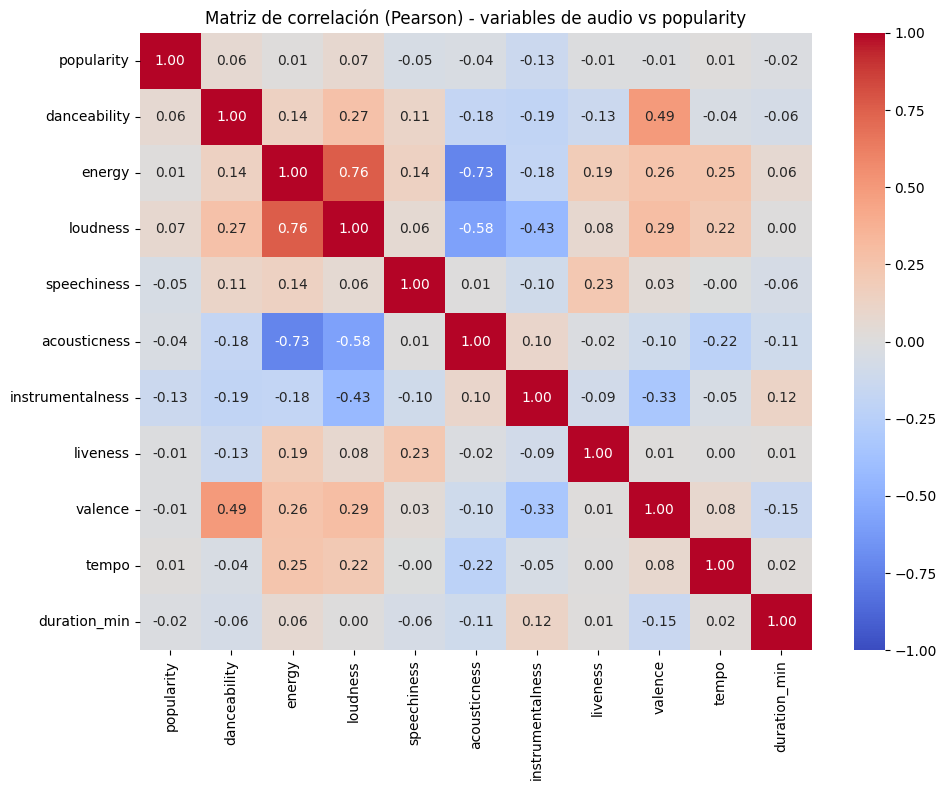

Correlación de cada variable con 'popularity':
popularity          1.000000
loudness            0.071705
danceability        0.064276
energy              0.013761
tempo               0.008817
valence            -0.011521
liveness           -0.013879
duration_min       -0.023165
acousticness       -0.038885
speechiness        -0.047082
instrumentalness   -0.127472
Name: popularity, dtype: float64


In [20]:
# Correlaciones calculadas sobre una observación por pista
columnas_numericas = [
    "popularity", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_min"
]

matriz_corr = BD_canciones[columnas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Matriz de correlación (Pearson) - variables de audio vs popularity")
plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "03_matriz_correlacion_pearson.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Correlación de cada variable con 'popularity':")
print(matriz_corr["popularity"].sort_values(ascending=False))


**Hallazgo clave del proyecto:** ninguna variable de audio muestra una correlación lineal fuerte con `popularity`. Al trabajar por `track_id` único, la relación de mayor magnitud sigue correspondiendo a `instrumentalness` y continúa siendo débil.

Esto indica que **ninguna característica de audio individual presenta una relación lineal fuerte con la popularidad**. No permite concluir todavía que el audio, considerado en conjunto, tenga poca capacidad de estimación: combinaciones de variables o relaciones no lineales podrían contener información que la correlación de Pearson no captura. Esa posibilidad se evaluará en la etapa de modelamiento.

Algunas características de audio contienen información parcialmente redundante, especialmente `energy`, `loudness` y `acousticness`. Esto deberá considerarse durante la elección e interpretación de los modelos.

### 8.2 Comparación de la popularidad promedio entre géneros musicales + Evaluación Ética.


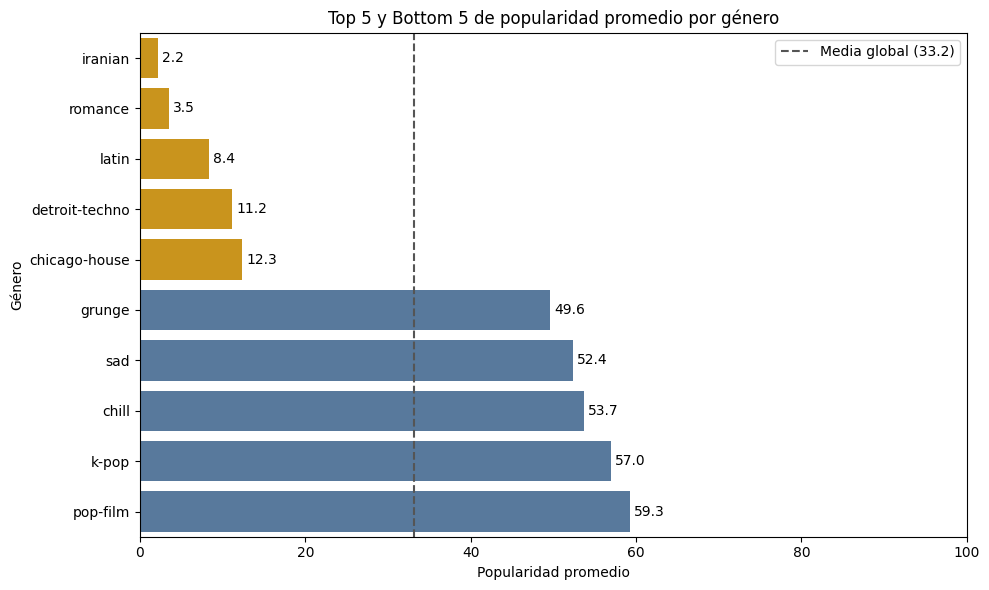

In [21]:
# Usar BD_generos porque aquí sí importa conservar la pertenencia múltiple a géneros
popularidad_genero = (
    BD_generos
    .groupby("track_genre")["popularity"]
    .mean()
    .sort_values()
)

comparacion_generos = pd.concat([
    popularidad_genero.head(5),
    popularidad_genero.tail(5)
])

# La línea de referencia se calcula sobre canciones únicas
media_global = BD_canciones["popularity"].mean()

colores = ["#E69F00"] * 5 + ["#4C78A8"] * 5

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=comparacion_generos.values,
    y=comparacion_generos.index,
    palette=colores,
    hue=comparacion_generos.index,
    legend=False
)

plt.axvline(
    media_global,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label=f"Media global ({media_global:.1f})"
)

plt.title("Top 5 y Bottom 5 de popularidad promedio por género")
plt.xlabel("Popularidad promedio")
plt.ylabel("Género")
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.legend()
plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "04_popularidad_promedio_genero.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


**Hallazgo y reflexión ética:** géneros como `k-pop` presentan una popularidad promedio mucho mayor que géneros como `iranian`, `romance` o `latin`. Estas diferencias describen el comportamiento observado en este dataset y **no deben interpretarse como diferencias de calidad musical**. Pueden estar relacionadas con factores como representación, exposición o presencia de Spotify en distintos mercados, pero este dataset no permite determinar cuál de esas causas explica las diferencias.

**Recomendación:** un modelo entrenado sobre `popularity` debe interpretarse como una estimación del comportamiento de consumo registrado en la plataforma, no como una medida de valor cultural o calidad musical.

### 8.3 Popularidad según contenido explícito


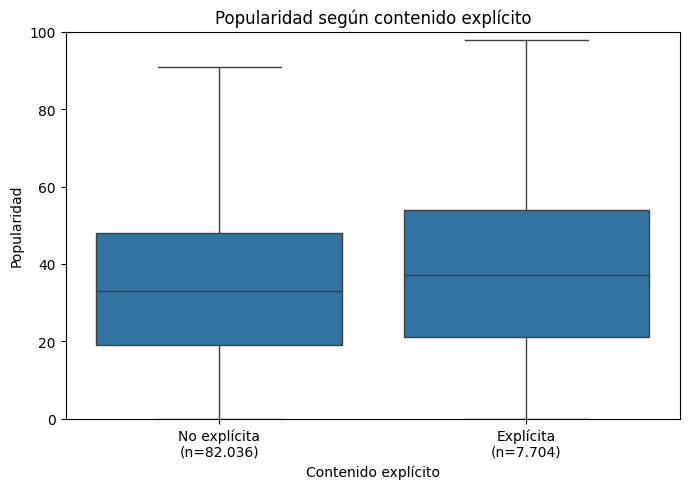

In [22]:
# Comparar popularity por contenido explícito usando una fila por canción
plt.figure(figsize=(7, 5))

ax = sns.boxplot(
    data=BD_canciones,
    x="explicit",
    y="popularity",
    showfliers=False
)

conteos = BD_canciones["explicit"].value_counts()

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"No explícita\n(n={conteos.get(False, 0):,})".replace(",", "."),
    f"Explícita\n(n={conteos.get(True, 0):,})".replace(",", ".")
])

plt.title("Popularidad según contenido explícito")
plt.xlabel("Contenido explícito")
plt.ylabel("Popularidad")
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "05_popularidad_contenido_explicito.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


**Hallazgo**: las canciones explícitas presentan una popularidad ligeramente superior, aunque existe una amplia superposición entre ambos grupos. Esto sugiere que el contenido explícito está asociado con diferencias pequeñas de popularidad, pero no constituye por sí solo un factor diferenciador fuerte.


### 8.4 Variabilidad de popularidad dentro de un mismo artista

¿Las canciones de un mismo artista tienen popularidad parecida, o hay mucha dispersión? Se agrupa por artista, filtrando solo quienes tienen 10 o más **tracks únicos** para evitar conclusiones con muestras chicas.


In [23]:
# Resumir la popularidad por artista contando cada track_id una sola vez
popularidad_artista = (
    BD_canciones
    .groupby("artists")["popularity"]
    .agg(
        cantidad="count",
        promedio="mean",
        desviacion="std",
        minimo="min",
        maximo="max"
    )
)

popularidad_artista = (
    popularidad_artista[
        popularidad_artista["cantidad"] >= 10
    ]
    .sort_values("desviacion", ascending=False)
)

print(
    "Artistas con al menos 10 tracks únicos:",
    popularidad_artista.shape[0]
)

popularidad_artista.head(10)


Artistas con al menos 10 tracks únicos: 1663


,cantidad,promedio,desviacion,minimo,maximo
artists,,,,,
The Weeknd,14,33.214286,43.193979,0.0,91.0
Taylor Swift,11,46.363636,42.842205,0.0,88.0
Ed Sheeran,13,27.384615,41.051875,0.0,88.0
Shawn Mendes,18,31.666667,40.024992,0.0,86.0
Imagine Dragons,31,39.419355,39.896344,0.0,89.0
Dua Lipa,12,46.083333,39.555389,0.0,84.0
The Killers,11,29.636364,39.251173,0.0,86.0
Lauren Spencer Smith,10,30.800000,39.057792,0.0,81.0
Melanie Martinez,17,31.647059,38.413769,0.0,80.0


**Hallazgo:** incluso después de contar cada pista una sola vez, algunos artistas con catálogos amplios presentan una dispersión muy alta de `popularity`. Entre los primeros casos aparecen artistas como The Weeknd, Taylor Swift, Ed Sheeran y Shawn Mendes.

Esto mantiene la idea general observada en la primera exploración: pertenecer a un artista conocido no implica que todas sus pistas tengan popularidades similares. Sin embargo, el ranking cambia al corregir la unidad de análisis, porque anteriormente algunas canciones multigénero podían contabilizarse más de una vez.

**Nota:** la agrupación utiliza el valor exacto de `artists`; una colaboración aparece como una categoría distinta de la carrera solista del artista.


### 8.5 Síntesis del análisis y preparación

Con el EDA y la revisión de calidad completados, quedan cerradas las etapas previas al modelamiento del flujo CRISP-DM:

| Etapa | Estado |
|---|---|
| Comprensión del negocio | Completa |
| Comprensión de los datos | Completa |
| Preparación de los datos | Completa |
| Modelado | Pendiente — EVA 2 |
| Evaluación | Pendiente — EVA 2 |
| Despliegue | Fuera del alcance actual |

La preparación deja dos estructuras con funciones distintas:

- `BD_canciones`: base analítica principal, con **una fila por `track_id`**.
- `BD_generos`: vista específica para conservar la relación **muchos-a-muchos entre canciones y géneros**.

Durante la preparación también se normalizaron los valores especiales de `tempo` y `time_signature`, y se definió la estrategia de imputación, codificación y escalamiento necesaria para los modelos.

La fase de Preparación se considera completa porque **las decisiones de transformación ya están definidas**. Los parámetros que dependen de los datos —por ejemplo, la mediana usada para imputar, las categorías del One-Hot Encoding o los parámetros de escalamiento— se ajustarán posteriormente dentro de los `Pipeline` correspondientes. En el flujo supervisado esto se hará únicamente con entrenamiento para evitar fuga de información.

La variabilidad de `popularity` en 720 pistas quedó identificada y documentada antes de modelar. Para construir `BD_canciones`, esas observaciones se consolidan mediante la mediana y se conservan `popularity_min`, `popularity_max`, `popularity_range` y `popularity_nunique` para mantener registro de esas diferencias.

El EDA mantiene como hallazgo principal que **ninguna característica de audio individual presenta una relación lineal fuerte con `popularity`**. Esto no descarta que combinaciones de variables o relaciones no lineales aporten capacidad de estimación, cuestión que corresponde evaluar en la siguiente etapa.

Con la unidad de análisis, la calidad de los datos y la estrategia de preparación ya definidas, el proyecto puede avanzar a **Modelado y Evaluación**.

## 9. Diseño de la etapa de modelamiento

Esta sección define el plan de modelamiento antes de entrenar los modelos: qué preguntas se responderán, qué información utilizará cada comparación, cómo se evaluarán los resultados y qué comparaciones se realizarán.

### 9.1 Preguntas y alcance del modelamiento

La etapa de modelamiento busca profundizar los hallazgos del análisis exploratorio mediante dos enfoques complementarios.

**Aprendizaje supervisado:** evaluar hasta qué punto las características disponibles de una canción permiten estimar el valor de `popularity` observado en el dataset. El objetivo no es pronosticar popularidad futura, ya que el dataset no contiene una dimensión temporal que permita comparar información disponible antes del lanzamiento con desempeño posterior.

**Aporte de información:** comparar cuánto aporta cada tipo de información disponible —características musicales y estructurales, género y su combinación— para identificar de dónde proviene realmente la capacidad de estimación.

**Aprendizaje no supervisado:** identificar perfiles o agrupaciones de canciones a partir de sus características de audio, sin utilizar `popularity` para construir los grupos. La popularidad podrá analizarse posteriormente como una característica descriptiva de los perfiles obtenidos.

Finalmente, ambos enfoques se integrarán para evaluar qué información aporta realmente el dataset al problema de priorización planteado y cuáles son sus limitaciones.


### 9.2 Datos y conjuntos de variables

La unidad de análisis se mantiene en `BD_canciones`: **una fila representa una pista identificada por un `track_id` único**.

Las decisiones de limpieza y preparación general ya fueron definidas en las fases anteriores. En esta sección solo se establece **qué información utilizará cada comparación de modelamiento**.

Para el aprendizaje supervisado se utiliza `popularity` como variable objetivo. Las variables candidatas se organizan por función:

- **Audio y estructura continua:** `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` y `duration_min`.
- **Características categóricas o binarias:** `explicit`, `mode_name`, `key_name` y `time_signature`.
- **Contexto:** `track_genres`, conservando la pertenencia multigénero de cada pista.

Se excluyen `track_id`, `artists`, `album_name` y `track_name` porque son identificadores o texto libre que podrían favorecer memorización en lugar de patrones generalizables. También se excluyen `popularity_min`, `popularity_max`, `popularity_range` y `popularity_nunique` porque se derivan directamente del target, y `n_genres` porque depende de la construcción particular del dataset.

Para estudiar el aporte de la información se consideran tres conjuntos conceptuales:

1. **Audio + estructura**
2. **Género**
3. **Audio + estructura + género**

Para el aprendizaje no supervisado se utilizarán exclusivamente características de audio continuas; `popularity` no participará en la construcción ni en la selección de los clusters.


In [24]:
# Variables definidas para la etapa de modelamiento
columnas_continuas = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_min"
]

columnas_categoricas = ["mode_name", "key_name", "time_signature"]
columnas_binarias = ["explicit"]
columna_generos = "track_genres"
target = "popularity"

columnas_modelo = (
    columnas_continuas
    + columnas_categoricas
    + columnas_binarias
    + [columna_generos, target]
)

# BD_modelo solo selecciona la información necesaria desde BD_canciones.
# La preparación ya fue definida previamente; sus parámetros se ajustarán
# posteriormente de forma segura dentro de los pipelines.
BD_modelo = BD_canciones[columnas_modelo].copy()

print("Filas de BD_modelo:", len(BD_modelo))
print("Valores de tempo pendientes de imputación:", BD_modelo["tempo"].isna().sum())
print(
    "Compases Unknown:",
    (BD_modelo["time_signature"] == "Unknown").sum()
)


Filas de BD_modelo: 89740
Valores de tempo pendientes de imputación: 157
Compases Unknown: 162


### 9.3 KPIs del proyecto y criterios de evaluación

El problema planteado busca apoyar la **priorización de canciones para promoción y playlists**. Por lo tanto, los indicadores relevantes deben reflejar si una priorización basada en datos permite seleccionar canciones con mejor desempeño, y no limitarse únicamente al rendimiento estadístico de un modelo.

#### KPIs propuestos para una decisión real de priorización

En una aplicación real, la organización debería definir previamente dos reglas:

- **Capacidad de priorización:** cuántas canciones puede seleccionar según sus recursos de promoción o espacios disponibles.
- **Criterio de desempeño:** qué resultado posterior se considerará satisfactorio para una canción priorizada.

A partir de estas reglas se proponen los siguientes KPIs:

| KPI propuesto | Pregunta que responde |
|---|---|
| **% de canciones priorizadas que alcanzan el desempeño esperado** | De las canciones seleccionadas, ¿qué proporción alcanzó posteriormente el resultado definido por la organización? |
| **% de canciones con buen desempeño que habían sido priorizadas** | De las canciones que finalmente tuvieron buen desempeño, ¿qué proporción había sido seleccionada previamente? |
| **Diferencia frente a una selección de referencia** | ¿Las canciones priorizadas mediante la solución obtienen, en promedio, un mejor resultado que una selección usada como referencia? |

El dataset disponible no contiene decisiones de promoción, capacidad de playlists ni mediciones posteriores a una intervención. Por ello, estos KPIs pueden **definirse**, pero no validarse directamente en esta evaluación sin inventar una capacidad de priorización, un criterio de desempeño o resultados futuros.

#### Criterios de evaluación posibles con los datos disponibles

La Evaluación Parcial N°2 se concentra en comprobar cuánta información útil contienen los datos disponibles para estimar `popularity`.

Para el aprendizaje supervisado se utilizarán **MAE como métrica principal**, **R² como métrica complementaria** y la **comparación con una referencia base o baseline**. En conjunto permiten cuantificar el error de estimación, la variabilidad de `popularity` que logra representar el modelo y si las características disponibles aportan información frente a una estimación que no aprende relaciones de los datos.

Estas medidas no son KPIs de negocio: son métricas técnicas para evaluar los modelos con los datos disponibles.

Para el aprendizaje no supervisado se utilizarán **inercia y Silhouette** para evaluar la estructura obtenida mediante K-Means. PCA se utilizará como apoyo para representar e interpretar los perfiles encontrados, considerando la proporción de varianza explicada.

In [25]:
# Función común de evaluación para los modelos de regresión
def evaluar_regresion(modelo, X_train, y_train, X_test, y_test):
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    return {
        "MAE train": mean_absolute_error(y_train, pred_train),
        "MAE test": mean_absolute_error(y_test, pred_test),
        "R2 train": r2_score(y_train, pred_train),
        "R2 test": r2_score(y_test, pred_test),
    }

resultados = {}
RES = {}


### 9.4 Estrategia de evaluación y control de fuga de datos

#### Aprendizaje supervisado

Se reserva un **80% para entrenamiento y un 20% para prueba**, utilizando `random_state=29` para mantener reproducibilidad. Como `BD_modelo` contiene una sola fila por `track_id`, una misma pista no puede aparecer simultáneamente en entrenamiento y prueba.

El conjunto de prueba queda reservado para la evaluación final. Las transformaciones que dependen de los datos —imputación, escalamiento y codificación— se ajustarán utilizando exclusivamente el conjunto de entrenamiento. De esta forma se evita que información del conjunto de prueba influya en el entrenamiento.

Cuando un modelo requiera selección de hiperparámetros, esta se realizará mediante validación cruzada dentro del conjunto de entrenamiento. El conjunto de prueba no participará en esa selección.

#### Aprendizaje no supervisado

El clustering utiliza el conjunto de canciones completo porque su propósito es explorar la estructura del catálogo, no estimar un error de predicción sobre una variable objetivo. Las variables de audio se escalarán antes de aplicar K-Means.

`popularity` no se utiliza para construir los clusters ni para seleccionar el número de grupos; solo se analiza después para describir los perfiles obtenidos.

In [26]:
# Separación única para todas las comparaciones supervisadas
idx_train, idx_test = train_test_split(
    BD_modelo.index,
    test_size=0.20,
    random_state=RANDOM_STATE
)

BD_train = BD_modelo.loc[idx_train].copy()
BD_test = BD_modelo.loc[idx_test].copy()

y_train = BD_train[target]
y_test = BD_test[target]

# Conjuntos sin transformar: el preprocesamiento se ajustará posteriormente solo con entrenamiento.
columnas_audio = columnas_continuas + columnas_categoricas + columnas_binarias

X_audio_train = BD_train[columnas_audio].copy()
X_audio_test = BD_test[columnas_audio].copy()

# Los géneros se codifican después del split para evitar aprender categorías desde el conjunto de prueba.
mlb_generos = MultiLabelBinarizer()
generos_train = pd.DataFrame(
    mlb_generos.fit_transform(BD_train[columna_generos]),
    columns=["gen_" + genero for genero in mlb_generos.classes_],
    index=BD_train.index
)
generos_test = pd.DataFrame(
    mlb_generos.transform(BD_test[columna_generos]),
    columns=generos_train.columns,
    index=BD_test.index
)

X_genero_train = generos_train
X_genero_test = generos_test

X_completo_train = pd.concat([X_audio_train, X_genero_train], axis=1)
X_completo_test = pd.concat([X_audio_test, X_genero_test], axis=1)

columnas_genero = list(generos_train.columns)

print("Entrenamiento:", len(BD_train))
print("Prueba:", len(BD_test))
print("Géneros codificados desde entrenamiento:", len(columnas_genero))


Entrenamiento: 71792
Prueba: 17948
Géneros codificados desde entrenamiento: 114


### 9.5 Referencia base (baseline) y plan de comparación

Antes de entrenar los modelos supervisados se establece una referencia simple que permita determinar si utilizar las características disponibles aporta información respecto de una estimación que no aprende relaciones de los datos.

Como **MAE es la métrica principal**, el baseline predice siempre la **mediana de `popularity` del conjunto de entrenamiento**, ya que es la predicción constante que minimiza el error absoluto.

El plan de comparación queda definido antes de observar los resultados:

#### Comparación 1 — Aporte de la información

Se utilizará Regresión Lineal manteniendo fijo el algoritmo y modificando únicamente la información disponible:

1. Audio + estructura
2. Género
3. Audio + estructura + género

Esto permitirá determinar de dónde proviene principalmente la capacidad de estimación.

#### Comparación 2 — Regresión Lineal vs Árbol de Decisión

Ambos modelos utilizarán el mismo conjunto combinado de variables, la misma partición train/test y las mismas métricas. De esta forma se evaluará si el Árbol de Decisión logra representar relaciones adicionales sin confundir el efecto del algoritmo con un cambio en las variables disponibles.

#### Análisis no supervisado

Se aplicará K-Means sobre características de audio estandarizadas. Se evaluarán distintos valores de `K` mediante inercia y Silhouette, y posteriormente se utilizará PCA como apoyo para visualizar e interpretar los perfiles obtenidos.

`popularity` no participará en la construcción ni en la selección de los clusters.

In [27]:
# Baseline supervisado:
# predicción constante igual a la mediana de popularity del conjunto de entrenamiento.
baseline = DummyRegressor(strategy="median")

# DummyRegressor requiere una matriz X, aunque no utiliza sus características.
X_dummy_train = np.zeros((len(y_train), 1))
X_dummy_test = np.zeros((len(y_test), 1))

baseline.fit(X_dummy_train, y_train)

resultados["Baseline (mediana)"] = evaluar_regresion(
    baseline,
    X_dummy_train,
    y_train,
    X_dummy_test,
    y_test
)

mae_baseline_test = resultados["Baseline (mediana)"]["MAE test"]

RES["filas_modelo"] = len(BD_modelo)
RES["filas_train"] = len(BD_train)
RES["filas_test"] = len(BD_test)
RES["n_generos"] = len(columnas_genero)
RES["mae_baseline_test"] = mae_baseline_test

print(f"Mediana de popularity en entrenamiento: {y_train.median():.1f}")
print(f"MAE baseline en test: {mae_baseline_test:.3f}")

pd.Series(resultados["Baseline (mediana)"]).round(3)


Mediana de popularity en entrenamiento: 33.0
MAE baseline en test: 17.117


MAE train    17.257
MAE test     17.117
R2 train     -0.000
R2 test      -0.000
dtype: float64

**Lectura del baseline:** esta referencia permite comprobar posteriormente si los modelos obtienen una mejora real frente a una estimación que no utiliza las características de las canciones. La comparación forma parte de la evaluación técnica del enfoque y no corresponde a un KPI de negocio.

El R² del baseline puede ser ligeramente negativo porque esta referencia utiliza la mediana, optimizada para MAE, en lugar de la media, que sería la referencia natural de R².


## 10. Modelos supervisados

La sección 9 definió dos comparaciones distintas para el aprendizaje supervisado. Primero se mantiene fijo el algoritmo para estudiar **qué información aporta capacidad de estimación**. Después se mantiene fija la información disponible para comparar **Regresión Lineal y Árbol de Decisión** bajo las mismas condiciones.


### 10.1 Regresión Lineal

La Regresión Lineal se utiliza como primer modelo por su simplicidad y porque permite mantener fija la forma del modelo mientras cambia únicamente la información disponible. Así se puede comparar el aporte de las características de audio y estructura, del género y de su combinación.

La estrategia de preparación necesaria para estas variables ya fue definida en la fase de **Preparación de los Datos**. En esta etapa se implementa mediante un pipeline para que la imputación, codificación y estandarización aprendan sus parámetros exclusivamente desde el conjunto de entrenamiento.


In [28]:
# Aplicar la estrategia de preparación definida previamente.
# Los parámetros de las transformaciones se ajustan solo con entrenamiento.
def crear_preprocesador_lineal(incluir_generos=False):
    numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ])

    categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=True
        ))
    ])

    transformaciones = [
        ("num", numerico, columnas_continuas),
        ("cat", categorico, columnas_categoricas),
        ("bin", "passthrough", columnas_binarias)
    ]

    if incluir_generos:
        transformaciones.append(("gen", "passthrough", columnas_genero))

    return ColumnTransformer(
        transformaciones,
        remainder="drop",
        verbose_feature_names_out=False
    )


def crear_lineal(incluir_generos=False):
    return Pipeline([
        ("prep", crear_preprocesador_lineal(incluir_generos)),
        ("modelo", LinearRegression())
    ])


#### 10.1.1 Comparación del aporte de la información

Se entrena el mismo algoritmo bajo tres configuraciones. Al mantener fija la Regresión Lineal, cualquier diferencia de desempeño puede atribuirse al tipo de información disponible y no al cambio de algoritmo.


In [29]:
# 1) Audio + estructura
lineal_audio = crear_lineal(incluir_generos=False)
lineal_audio.fit(X_audio_train, y_train)
resultados["Regresión Lineal (audio + estructura)"] = evaluar_regresion(
    lineal_audio,
    X_audio_train,
    y_train,
    X_audio_test,
    y_test
)

# 2) Género
lineal_genero = LinearRegression()
lineal_genero.fit(X_genero_train, y_train)
resultados["Regresión Lineal (género)"] = evaluar_regresion(
    lineal_genero,
    X_genero_train,
    y_train,
    X_genero_test,
    y_test
)

# 3) Audio + estructura + género
lineal_completo = crear_lineal(incluir_generos=True)
lineal_completo.fit(X_completo_train, y_train)
resultados["Regresión Lineal (combinado)"] = evaluar_regresion(
    lineal_completo,
    X_completo_train,
    y_train,
    X_completo_test,
    y_test
)

filas_lineales = [
    "Baseline (mediana)",
    "Regresión Lineal (audio + estructura)",
    "Regresión Lineal (género)",
    "Regresión Lineal (combinado)"
]

tabla_informacion = pd.DataFrame(
    {nombre: resultados[nombre] for nombre in filas_lineales}
).T

tabla_informacion["Reducción MAE vs baseline (%)"] = (
    (mae_baseline_test - tabla_informacion["MAE test"])
    / mae_baseline_test * 100
)

tabla_informacion.round(3)


,MAE train,MAE test,R2 train,R2 test,Reducción MAE vs baseline (%)
Baseline (mediana),17.257,17.117,-0.000,-0.000,0.000
Regresión Lineal (audio + estructura),16.658,16.516,0.036,0.035,3.512
Regresión Lineal (género),11.877,11.887,0.353,0.349,30.556
Regresión Lineal (combinado),11.811,11.833,0.358,0.351,30.873


**Interpretación:** las características de audio y estructura, utilizadas por sí solas, mejoran muy poco respecto del baseline: el MAE disminuye solo un 3,5% y el modelo explica cerca del 3,5% de la variabilidad de `popularity`.

Al incorporar únicamente la información de género, el desempeño cambia considerablemente: el MAE baja de 17,12 a 11,89 puntos y el R² aumenta hasta aproximadamente 0,35.

El modelo combinado obtiene el mejor resultado de las tres configuraciones, pero su mejora respecto de usar solo género es mínima (`MAE: 11,89 → 11,83`; `R²: 0,349 → 0,351`).

Por lo tanto, dentro de la Regresión Lineal, **la mayor parte de la capacidad de estimación proviene de la información de género**. Las características de audio y estructura aportan poca información adicional una vez conocido el género.

In [30]:
# Predicciones de las tres configuraciones sobre las mismas canciones del test
pred_audio = lineal_audio.predict(X_audio_test)
pred_genero = lineal_genero.predict(X_genero_test)
pred_combinado = lineal_completo.predict(X_completo_test)

# Tabla 1: comparación directa de predicciones
comparacion_predicciones = pd.DataFrame({
    "real": y_test.values,
    "pred_audio": pred_audio,
    "pred_genero": pred_genero,
    "pred_combinado": pred_combinado
})

display(comparacion_predicciones.head(10).round(2))

# Tabla 2: errores absolutos de esas mismas predicciones
comparacion_errores = pd.DataFrame({
    "real": y_test.values,
    "error_audio": np.abs(y_test.values - pred_audio),
    "error_genero": np.abs(y_test.values - pred_genero),
    "error_combinado": np.abs(y_test.values - pred_combinado)
})

display(comparacion_errores.head(10).round(2))

# Conexión directa con el MAE:
# el MAE es el promedio de los errores absolutos de cada configuración
print("MAE audio + estructura:", round(comparacion_errores["error_audio"].mean(), 3))
print("MAE género:", round(comparacion_errores["error_genero"].mean(), 3))
print("MAE combinado:", round(comparacion_errores["error_combinado"].mean(), 3))

,real,pred_audio,pred_genero,pred_combinado
0,0.0,28.45,47.95,46.51
1,1.0,34.27,29.34,27.12
2,48.0,37.24,52.52,53.20
3,25.0,31.56,24.43,23.38
4,0.0,37.82,24.70,25.98
5,58.0,39.08,41.90,44.58
6,52.0,32.13,43.75,45.20
7,45.0,30.60,26.14,27.02
8,74.0,40.65,40.86,42.16
9,19.0,38.66,27.42,29.86


,real,error_audio,error_genero,error_combinado
0,0.0,28.45,47.95,46.51
1,1.0,33.27,28.34,26.12
2,48.0,10.76,4.52,5.20
3,25.0,6.56,0.57,1.62
4,0.0,37.82,24.70,25.98
5,58.0,18.92,16.10,13.42
6,52.0,19.87,8.25,6.80
7,45.0,14.40,18.86,17.98
8,74.0,33.35,33.14,31.84
9,19.0,19.66,8.42,10.86


MAE audio + estructura: 16.516
MAE género: 11.887
MAE combinado: 11.833


Las predicciones individuales permiten observar cómo se construyen las métricas anteriores: el MAE corresponde al promedio de los errores absolutos de todas las canciones del conjunto de prueba.

Las primeras filas también muestran que el error puede variar considerablemente entre canciones. Por ello, estos ejemplos se utilizan únicamente para hacer visible el funcionamiento de la evaluación; las conclusiones sobre desempeño se basan en el conjunto de prueba completo y no en estas diez observaciones.

In [31]:
mask_cero = y_test == 0

mae_cero = mean_absolute_error(
    y_test[mask_cero],
    pred_combinado[mask_cero]
)

mae_no_cero = mean_absolute_error(
    y_test[~mask_cero],
    pred_combinado[~mask_cero]
)

print("MAE popularity = 0:", round(mae_cero, 2))
print("MAE popularity > 0:", round(mae_no_cero, 2))

MAE popularity = 0: 24.65
MAE popularity > 0: 10.38


#### 10.1.2 Interpretación de la Regresión Lineal

Los coeficientes del modelo combinado permiten describir las asociaciones que la Regresión Lineal aprendió entre las variables y `popularity`, manteniendo constantes las demás características.

En las variables continuas, los coeficientes corresponden a cambios de una desviación estándar porque fueron estandarizadas. En variables como tonalidad, modo y compás, los coeficientes se interpretan respecto de la categoría de referencia utilizada por el One-Hot Encoding.

Los géneros, en cambio, se representan como indicadores independientes debido a que una canción puede pertenecer a más de uno. Sus coeficientes muestran asociaciones dentro del modelo, pero **no significan que un género cause un cambio en `popularity` ni representan diferencias de calidad musical**.

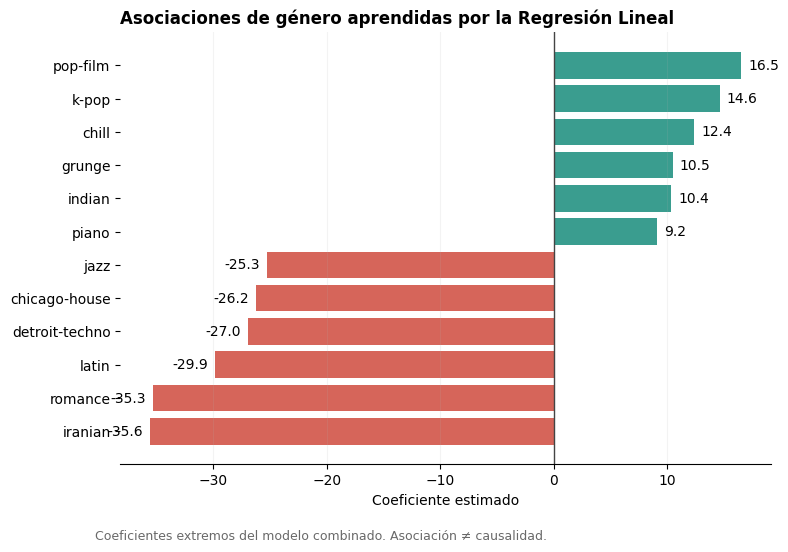

gen_iranian          -35.58
gen_romance          -35.33
gen_latin            -29.85
gen_detroit-techno   -26.97
gen_chicago-house    -26.21
gen_jazz             -25.25
gen_piano              9.15
gen_indian            10.38
gen_grunge            10.50
gen_chill             12.42
gen_k-pop             14.64
gen_pop-film          16.54
dtype: float64

In [32]:
# Paleta común para las visualizaciones supervisadas
COLOR_LINEAL = "#3B82B8"
COLOR_ARBOL = "#4C956C"
COLOR_BASELINE = "#8A8A8A"
COLOR_ALERTA = "#D95F59"
COLOR_POSITIVO = "#3A9D8F"
COLOR_NEGATIVO = "#D6655A"
COLOR_REFERENCIA = "#444444"

# Coeficientes asociados a los géneros en el modelo combinado
nombres_lineal = lineal_completo.named_steps["prep"].get_feature_names_out()

coef_lineal = pd.Series(
    lineal_completo.named_steps["modelo"].coef_,
    index=nombres_lineal
).sort_values()

coef_generos = coef_lineal[
    coef_lineal.index.str.startswith("gen_")
]

# Mostrar solo los extremos
coef_generos_extremos = pd.concat([
    coef_generos.head(6),
    coef_generos.tail(6)
]).sort_values()

# Nombres más limpios para visualizar
coef_plot = coef_generos_extremos.copy()
coef_plot.index = coef_plot.index.str.replace("gen_", "", regex=False)

colores = [
    COLOR_NEGATIVO if valor < 0 else COLOR_POSITIVO
    for valor in coef_plot.values
]

fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.barh(
    coef_plot.index,
    coef_plot.values,
    color=colores
)

ax.axvline(0, color=COLOR_REFERENCIA, linewidth=1)

# Mostrar el valor de cada coeficiente
for bar, valor in zip(bars, coef_plot.values):
    if valor >= 0:
        ax.text(
            valor + 0.6,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:.1f}",
            va="center"
        )
    else:
        ax.text(
            valor - 0.6,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:.1f}",
            va="center",
            ha="right"
        )

ax.set_xlabel("Coeficiente estimado")
ax.set_ylabel("")
ax.set_title(
    "Asociaciones de género aprendidas por la Regresión Lineal",
    loc="left",
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.15)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.figtext(
    0.125, 0.01,
    "Coeficientes extremos del modelo combinado. Asociación ≠ causalidad.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    IMAGES_DIR / "10_coeficientes_generos.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

RES["coef_generos_extremos"] = {
    k.replace("gen_", ""): float(v)
    for k, v in coef_generos_extremos.items()
}

coef_generos_extremos.round(2)

Los coeficientes muestran asociaciones marcadas entre algunos géneros y la `popularity` estimada por el modelo. Por ejemplo, `pop-film` y `k-pop` aparecen asociados a valores mayores, mientras que `iranian`, `romance` y `latin` presentan asociaciones negativas dentro de esta muestra.

Estos resultados son coherentes con las diferencias por género observadas durante el EDA, pero no demuestran que un género cause mayor o menor popularidad. También pueden reflejar características propias de la composición y representación del dataset de Spotify utilizado.

In [33]:
# Diagnóstico de dominio:
# la Regresión Lineal no está restringida matemáticamente al intervalo 0-100.
pred_lineal_test = lineal_completo.predict(X_completo_test)

fuera_rango = (
    (pred_lineal_test < 0)
    | (pred_lineal_test > 100)
)

RES["lineal_fuera_rango"] = int(fuera_rango.sum())

print("Predicciones fuera del rango 0-100:", int(fuera_rango.sum()))
print("Porcentaje:", round(fuera_rango.mean() * 100, 2), "%")
print("Predicción mínima:", round(pred_lineal_test.min(), 2))
print("Predicción máxima:", round(pred_lineal_test.max(), 2))


Predicciones fuera del rango 0-100: 82
Porcentaje: 0.46 %
Predicción mínima: -21.99
Predicción máxima: 77.9


La Regresión Lineal no restringe matemáticamente sus predicciones al intervalo válido de `popularity` (0–100). En este caso, 82 predicciones del conjunto de prueba quedan fuera de ese rango, equivalentes a aproximadamente el 0,46%.

La proporción es pequeña, por lo que no constituye el principal problema del modelo, pero evidencia una limitación de utilizar una salida lineal para una variable acotada.

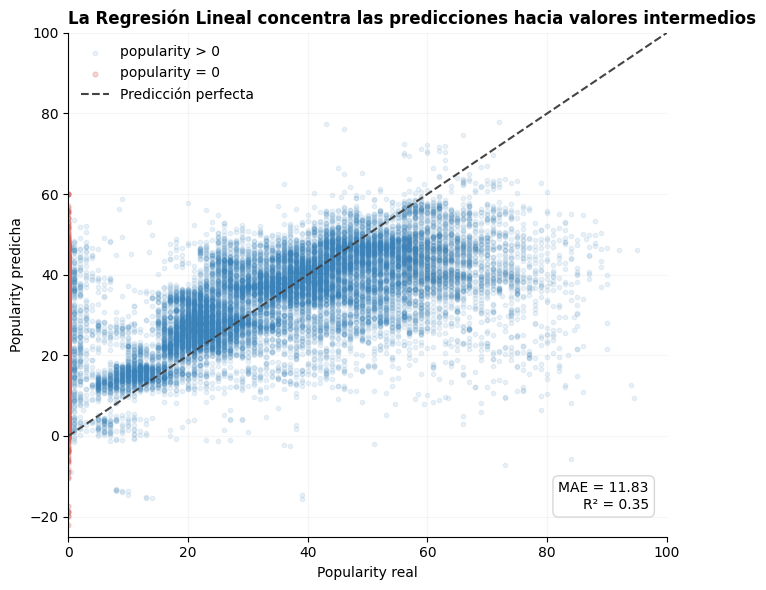

In [34]:
pred_combinado = lineal_completo.predict(X_completo_test)

real_test = y_test.to_numpy()
mask_cero = real_test == 0

mae_lineal = resultados["Regresión Lineal (combinado)"]["MAE test"]
r2_lineal = resultados["Regresión Lineal (combinado)"]["R2 test"]

fig, ax = plt.subplots(figsize=(7, 6))

# Canciones con popularity > 0
ax.scatter(
    real_test[~mask_cero],
    pred_combinado[~mask_cero],
    s=10,
    alpha=0.10,
    color=COLOR_LINEAL,
    label="popularity > 0",
    rasterized=True
)

# Casos popularity = 0
ax.scatter(
    real_test[mask_cero],
    pred_combinado[mask_cero],
    s=12,
    alpha=0.25,
    color=COLOR_ALERTA,
    label="popularity = 0",
    rasterized=True
)

# Predicción perfecta
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1.5,
    color=COLOR_REFERENCIA,
    label="Predicción perfecta"
)

ax.text(
    0.97, 0.05,
    f"MAE = {mae_lineal:.2f}\nR² = {r2_lineal:.2f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9
    )
)

ax.set_xlim(0, 100)
ax.set_ylim(-25, 100)

ax.set_xlabel("Popularity real")
ax.set_ylabel("Popularity predicha")

ax.set_title(
    "La Regresión Lineal concentra las predicciones hacia valores intermedios",
    loc="left",
    fontweight="bold"
)

ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.12)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "11_lineal_real_vs_predicho.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

**Interpretación del desempeño:** la Regresión Lineal combinada captura parte de las diferencias de `popularity`, pero las predicciones tienden a concentrarse hacia valores intermedios. Esto se observa especialmente en los extremos: las canciones de popularidad alta suelen ser subestimadas, mientras que muchas canciones con popularidad muy baja o igual a cero son sobreestimadas.

El diagnóstico por separado confirma esta dificultad. Para las canciones con `popularity = 0`, el MAE alcanza **24,65 puntos**, frente a **10,38 puntos** en las canciones con valores superiores a cero. Estos registros se mantienen porque forman parte de los valores observados del dataset y no existe evidencia suficiente para considerarlos errores.

En conjunto, el modelo combinado obtiene un **MAE de aproximadamente 11,83 puntos** y un **R² de 0,35**. Por tanto, existe información útil para estimar `popularity`, especialmente a partir del género, pero una parte importante de la variabilidad permanece sin explicar y el modelo presenta dificultades para representar los valores extremos.

### 10.2 Árbol de Decisión

El Árbol de Decisión permite representar relaciones no lineales e interacciones entre variables. Para que la comparación con la Regresión Lineal sea justa, utiliza el mismo conjunto combinado de información.

La estrategia de preparación ya fue definida en la fase anterior. Para el Árbol se aplican la imputación y la codificación necesarias, pero **no se estandarizan las variables continuas**, porque este algoritmo no depende de distancias ni de la escala de las características.

Su complejidad se selecciona mediante validación cruzada exclusivamente dentro del conjunto de entrenamiento. Como MAE fue definido en la sección 9 como métrica principal, la búsqueda de hiperparámetros también se optimiza según MAE. El conjunto de prueba permanece reservado para la evaluación final.


In [35]:
# Aplicar la preparación definida previamente para el Árbol:
# imputación y codificación, sin escalamiento.
def crear_preprocesador_arbol():
    numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median"))
    ])

    categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=True
        ))
    ])

    return ColumnTransformer(
        [
            ("num", numerico, columnas_continuas),
            ("cat", categorico, columnas_categoricas),
            ("bin", "passthrough", columnas_binarias),
            ("gen", "passthrough", columnas_genero)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )


pipeline_arbol = Pipeline([
    ("prep", crear_preprocesador_arbol()),
    ("modelo", DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ))
])

# Búsqueda acotada: compara complejidad moderada, mayor y sin límite explícito
# de profundidad, manteniendo regularización mediante min_samples_leaf.
parametros_arbol = {
    "modelo__max_depth": [12, 20, None],
    "modelo__min_samples_leaf": [10, 30]
}

busqueda_arbol = GridSearchCV(
    pipeline_arbol,
    parametros_arbol,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

busqueda_arbol.fit(X_completo_train, y_train)

arbol_completo = busqueda_arbol.best_estimator_

resultados["Árbol de Decisión (combinado)"] = evaluar_regresion(
    arbol_completo,
    X_completo_train,
    y_train,
    X_completo_test,
    y_test
)

RES["arbol_params"] = {
    k.replace("modelo__", ""): v
    for k, v in busqueda_arbol.best_params_.items()
}
RES["arbol_mae_cv"] = float(
    -busqueda_arbol.best_score_
)

print("Mejores hiperparámetros:", RES["arbol_params"])
print(
    "MAE promedio en validación cruzada:",
    round(-busqueda_arbol.best_score_, 3)
)

pd.Series(
    resultados["Árbol de Decisión (combinado)"]
).round(3)


Mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 30}
MAE promedio en validación cruzada: 11.471


MAE train     9.731
MAE test     11.159
R2 train      0.517
R2 test       0.368
dtype: float64

**Interpretación:** el Árbol de Decisión obtiene un mejor desempeño que la Regresión Lineal combinada. En el conjunto de prueba reduce el MAE de aproximadamente **11,83 a 11,16 puntos** y aumenta el R² de **0,35 a 0,37**.

Esto **sugiere que existen relaciones no lineales o combinaciones entre variables** que la Regresión Lineal no logra representar completamente. Sin embargo, la mejora es moderada, por lo que el cambio de algoritmo aporta menos que la incorporación de información de género observada anteriormente.

La diferencia entre entrenamiento y prueba es mayor en el Árbol (`MAE 9,73 vs. 11,16`; `R² 0,52 vs. 0,37`), lo que muestra una mayor tendencia al sobreajuste que en la Regresión Lineal. La restricción `min_samples_leaf = 30` ayuda a limitar esa complejidad.

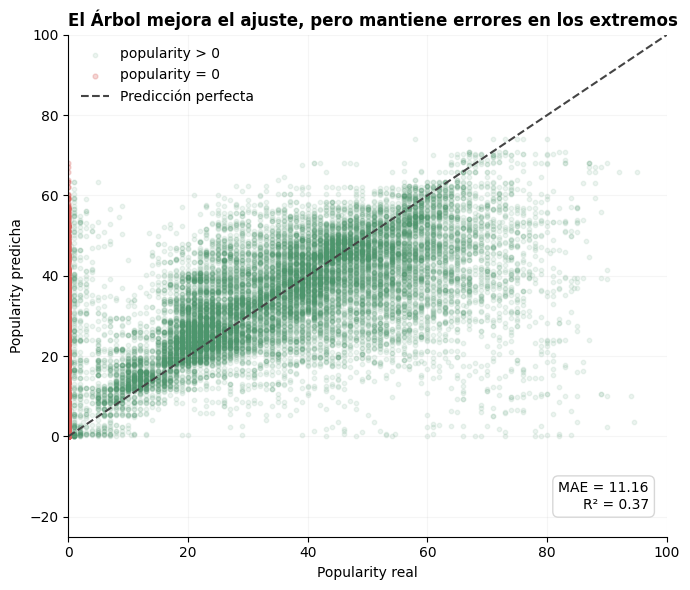

In [36]:
pred_arbol = arbol_completo.predict(X_completo_test)

mae_arbol = resultados["Árbol de Decisión (combinado)"]["MAE test"]
r2_arbol = resultados["Árbol de Decisión (combinado)"]["R2 test"]

fig, ax = plt.subplots(figsize=(7, 6))

# Canciones con popularity > 0
ax.scatter(
    real_test[~mask_cero],
    pred_arbol[~mask_cero],
    s=10,
    alpha=0.10,
    color=COLOR_ARBOL,
    label="popularity > 0",
    rasterized=True
)

# Casos popularity = 0
ax.scatter(
    real_test[mask_cero],
    pred_arbol[mask_cero],
    s=12,
    alpha=0.25,
    color=COLOR_ALERTA,
    label="popularity = 0",
    rasterized=True
)

# Predicción perfecta
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1.5,
    color=COLOR_REFERENCIA,
    label="Predicción perfecta"
)

ax.text(
    0.97, 0.05,
    f"MAE = {mae_arbol:.2f}\nR² = {r2_arbol:.2f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9
    )
)

# Mismos límites que la Regresión Lineal
ax.set_xlim(0, 100)
ax.set_ylim(-25, 100)

ax.set_xlabel("Popularity real")
ax.set_ylabel("Popularity predicha")

ax.set_title(
    "El Árbol mejora el ajuste, pero mantiene errores en los extremos",
    loc="left",
    fontweight="bold"
)

ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.12)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "12_arbol_real_vs_predicho.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

**Interpretación:** la línea diagonal representa una predicción perfecta: cuanto más cerca se encuentra un punto de ella, menor es el error.

El Árbol de Decisión sigue correctamente parte de la tendencia general de `popularity`, aunque mantiene una dispersión importante. En comparación con la Regresión Lineal, consigue un ajuste algo mejor, coherente con su menor MAE y mayor R².

Sin embargo, continúan observándose dificultades en los extremos. Muchas canciones con popularidad alta son subestimadas y las canciones con valores muy bajos, especialmente `popularity = 0`, presentan predicciones muy dispersas. Por lo tanto, el Árbol mejora la estimación, pero no elimina las principales dificultades observadas en el problema.

#### 10.2.1 Diagnóstico del Árbol

La importancia de variables se conserva únicamente como una descripción complementaria del funcionamiento del Árbol seleccionado. No se interpreta como prueba de que una variable cause cambios en `popularity` ni sustituye la comparación de conjuntos de información realizada con la Regresión Lineal.

In [37]:
nombres_arbol = (
    arbol_completo
    .named_steps["prep"]
    .get_feature_names_out()
)

importancias_arbol = pd.Series(
    arbol_completo.named_steps["modelo"].feature_importances_,
    index=nombres_arbol
).sort_values(ascending=False)

RES["imp_arbol"] = {
    k: float(v)
    for k, v in importancias_arbol.head(8).items()
}

importancias_arbol.head(8).to_frame(
    "Importancia"
).round(3)


,Importancia
gen_iranian,0.050
gen_romance,0.042
duration_min,0.041
acousticness,0.034
gen_pop-film,0.034
loudness,0.034
gen_latin,0.032
danceability,0.026


Las importancias muestran qué variables fueron utilizadas con mayor frecuencia o utilidad por el Árbol para realizar sus divisiones. Aparecen tanto variables de género como características de audio y estructura, lo que indica que el modelo combina distintos tipos de información.

Estas importancias describen el funcionamiento interno del Árbol y **no significan que las variables provoquen directamente cambios en `popularity`**.

### 10.3 Comparación e interpretación

La comparación final se separa en dos preguntas para no mezclar el efecto de cambiar la información disponible con el efecto de cambiar el algoritmo.


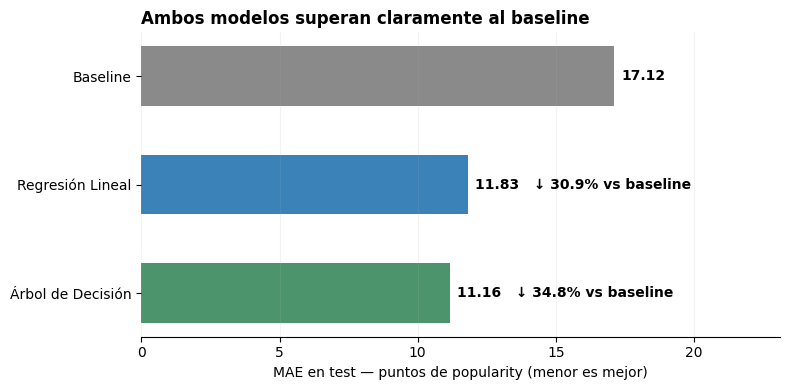

In [38]:
comparacion_mae = pd.Series({
    "Baseline": resultados["Baseline (mediana)"]["MAE test"],
    "Regresión Lineal": resultados["Regresión Lineal (combinado)"]["MAE test"],
    "Árbol de Decisión": resultados["Árbol de Decisión (combinado)"]["MAE test"]
})

colores = [
    COLOR_BASELINE,
    COLOR_LINEAL,
    COLOR_ARBOL
]

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(
    comparacion_mae.index,
    comparacion_mae.values,
    color=colores,
    height=0.55
)

baseline_mae = comparacion_mae["Baseline"]

for nombre, bar, valor in zip(
    comparacion_mae.index,
    bars,
    comparacion_mae.values
):
    texto = f"{valor:.2f}"

    if nombre != "Baseline":
        mejora = (baseline_mae - valor) / baseline_mae * 100
        texto += f"   ↓ {mejora:.1f}% vs baseline"

    ax.text(
        valor + 0.25,
        bar.get_y() + bar.get_height() / 2,
        texto,
        va="center",
        fontweight="bold"
    )

ax.invert_yaxis()

ax.set_xlim(0, comparacion_mae.max() * 1.35)
ax.set_xlabel("MAE en test — puntos de popularity (menor es mejor)")
ax.set_ylabel("")

ax.set_title(
    "Ambos modelos superan claramente al baseline",
    loc="left",
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.15)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "13_comparacion_mae_supervisados.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

**Interpretación:** el baseline presenta el mayor error, con un MAE cercano a **17,12 puntos**. La Regresión Lineal reduce este error hasta aproximadamente **11,83**, mientras que el Árbol de Decisión obtiene el menor MAE, cercano a **11,16 puntos**.

Esto muestra que utilizar las características disponibles aporta una mejora clara respecto de una estimación que no aprende de los datos. El Árbol mejora adicionalmente respecto de la Regresión Lineal, aunque la diferencia entre ambos modelos es bastante menor que la mejora obtenida al pasar del baseline a un modelo entrenado.

In [39]:
# Comparación 1: qué información aporta a la Regresión Lineal
tabla_aporte_final = tabla_informacion[
    ["MAE test", "R2 test", "Reducción MAE vs baseline (%)"]
].copy()

# Comparación 2: mismo conjunto de información, distinto modelo
filas_modelos = [
    "Baseline (mediana)",
    "Regresión Lineal (combinado)",
    "Árbol de Decisión (combinado)"
]

tabla_modelos_final = pd.DataFrame(
    {nombre: resultados[nombre] for nombre in filas_modelos}
).T[["MAE test", "R2 test"]]

tabla_modelos_final["Reducción MAE vs baseline (%)"] = (
    (mae_baseline_test - tabla_modelos_final["MAE test"])
    / mae_baseline_test * 100
)

print("1. ¿Qué información aporta?")
display(tabla_aporte_final.round(3))

print("\n2. ¿Qué modelo obtiene mejor desempeño?")
display(tabla_modelos_final.round(3))

1. ¿Qué información aporta?


,MAE test,R2 test,Reducción MAE vs baseline (%)
Baseline (mediana),17.117,-0.000,0.000
Regresión Lineal (audio + estructura),16.516,0.035,3.512
Regresión Lineal (género),11.887,0.349,30.556
Regresión Lineal (combinado),11.833,0.351,30.873



2. ¿Qué modelo obtiene mejor desempeño?


,MAE test,R2 test,Reducción MAE vs baseline (%)
Baseline (mediana),17.117,-0.000,0.000
Regresión Lineal (combinado),11.833,0.351,30.873
Árbol de Decisión (combinado),11.159,0.368,34.805


### Conclusión de los modelos supervisados

Los resultados permiten responder dos preguntas diferentes.

**1. ¿Qué información aporta capacidad de estimación?**

Las características de audio y estructura por sí solas aportan poca capacidad de estimación: la Regresión Lineal reduce el MAE solo un **3,5%** frente al baseline y obtiene un `R² ≈ 0,04`.

La incorporación del género produce el cambio principal: con género solamente, la reducción del MAE alcanza aproximadamente **30,6%** y el `R²` aumenta hasta **0,35**. Agregar audio y estructura sobre el género mejora muy poco estos resultados.

Por tanto, **la mayor parte de la información útil disponible para estimar `popularity` proviene del género y no de las características de audio consideradas**.

**2. ¿Qué modelo obtiene mejor desempeño con la misma información?**

Utilizando el conjunto combinado de variables, el **Árbol de Decisión obtiene el mejor resultado**:

- Regresión Lineal: `MAE = 11,83`, `R² = 0,35`.
- Árbol de Decisión: `MAE = 11,16`, `R² = 0,37`.

El Árbol logra representar relaciones adicionales que la Regresión Lineal no captura completamente, aunque la mejora es moderada.

**Conclusión general:** el Árbol de Decisión es el mejor de los dos modelos supervisados evaluados, pero el hallazgo más relevante no es el cambio de algoritmo, sino **qué información está disponible para el modelo**. El género concentra gran parte de la capacidad de estimación, mientras que el audio por sí solo aporta poco para estimar `popularity`.

Aun con el mejor modelo, queda una parte importante de la variabilidad sin explicar y persisten errores relevantes, especialmente en valores extremos y en canciones con `popularity = 0`. Por ello, los resultados permiten usar el modelo como **apoyo para analizar el dataset**, pero no permiten afirmar que pueda anticipar por sí solo el desempeño futuro de una canción ni reemplazar una decisión de promoción.

## 11. Aprendizaje no supervisado


### 11.1 Preparación para clustering


Para el análisis no supervisado se utilizan **9 características continuas de audio**:

- `danceability`
- `energy`
- `loudness`
- `speechiness`
- `acousticness`
- `instrumentalness`
- `liveness`
- `valence`
- `tempo`

La selección responde al objetivo de identificar **perfiles sonoros**. Por esta razón no se incluyen `popularity` ni `track_genres`: la primera se utilizará únicamente después para describir los grupos obtenidos y el género corresponde a información contextual ya conocida.

Tampoco se incorporan variables categóricas como tonalidad, modo o compás. Como K-Means forma los grupos a partir de distancias, incluir estas variables requeriría otra forma de representarlas y cambiaría la manera en que se calculan esas distancias. `duration_min` se mantiene fuera porque describe principalmente la duración de la pista y no una característica sonora del perfil que se busca construir.

Las variables se estandarizan para evitar que características con escalas mayores, como `tempo` o `loudness`, dominen la formación de los grupos. Los valores faltantes de `tempo` se imputan mediante la mediana, siguiendo la estrategia definida previamente en Preparación de los Datos.

In [40]:
# Variables utilizadas exclusivamente para clustering
columnas_cluster = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X_cluster = BD_modelo[columnas_cluster].copy()

# Aplicar la estrategia de preparación definida previamente:
# imputación de faltantes + estandarización.
prep_cluster = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

X_cluster_sc = prep_cluster.fit_transform(X_cluster)

print("Forma de la matriz para clustering:", X_cluster_sc.shape)
print(
    "Media tras escalar:",
    np.round(X_cluster_sc.mean(axis=0), 2)
)
print(
    "Desviación estándar tras escalar:",
    np.round(X_cluster_sc.std(axis=0), 2)
)

Forma de la matriz para clustering: (89740, 9)
Media tras escalar: [-0. -0.  0.  0. -0. -0. -0. -0.  0.]
Desviación estándar tras escalar: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 11.2 Selección del número de clusters


K según método del codo: 4
K según máxima Silhouette: 2


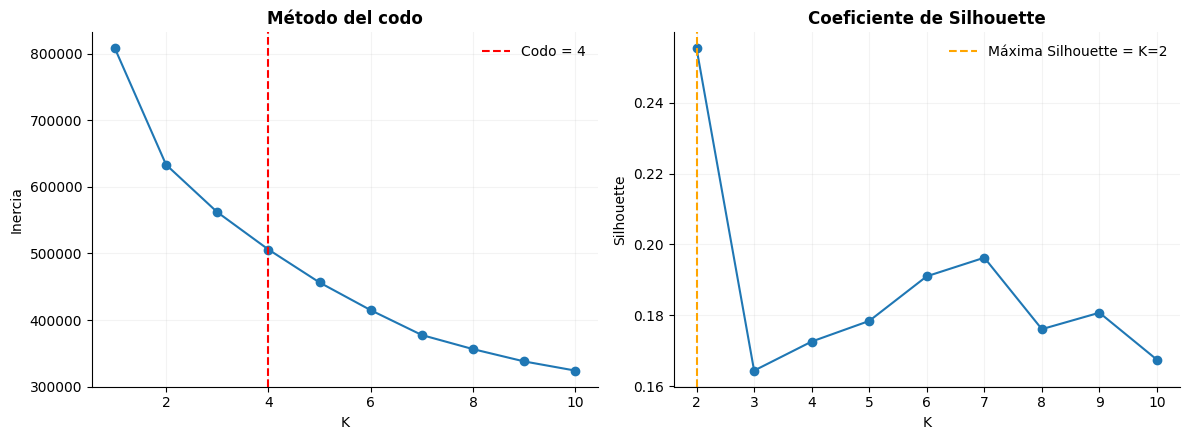

In [41]:

# Evaluación del número de clusters para K-Means
# Inercia: K = 1 a 10
# Silhouette: K = 2 a 10

ks_inercia = list(range(1, 11))
ks_silueta = list(range(2, 11))

inercias = []
siluetas = []

for k in ks_inercia:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    km.fit(X_cluster_sc)
    inercias.append(km.inertia_)

for k in ks_silueta:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = km.fit_predict(X_cluster_sc)

    siluetas.append(
        silhouette_score(
            X_cluster_sc,
            labels,
            sample_size=10000,
            random_state=RANDOM_STATE
        )
    )

# Método del codo
kl = KneeLocator(
    ks_inercia,
    inercias,
    curve="convex",
    direction="decreasing"
)

k_codo = kl.elbow
k_silueta = ks_silueta[int(np.argmax(siluetas))]

print("K según método del codo:", k_codo)
print("K según máxima Silhouette:", k_silueta)

# Visualización de ambos criterios por separado
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Inercia
axes[0].plot(ks_inercia, inercias, marker="o")

if k_codo is not None:
    axes[0].axvline(
        k_codo,
        linestyle="--",
        color="red",
        label=f"Codo = {k_codo}"
    )

axes[0].set_title("Método del codo", fontweight="bold")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.15)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)

# Silhouette
axes[1].plot(ks_silueta, siluetas, marker="o")

axes[1].axvline(
    k_silueta,
    linestyle="--",
    color="orange",
    label=f"Máxima Silhouette = K={k_silueta}"
)

axes[1].set_title("Coeficiente de Silhouette", fontweight="bold")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
axes[1].grid(alpha=0.15)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.savefig(
    IMAGES_DIR / "14_kmeans_seleccion_k.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

RES["inercias"] = [float(x) for x in inercias]
RES["siluetas"] = [float(x) for x in siluetas]
RES["k_elbow"] = int(k_codo) if k_codo is not None else None
RES["k_silueta_max"] = int(k_silueta)

**Selección de K:** los dos criterios utilizados no entregan exactamente la misma respuesta.

- El mayor coeficiente de Silhouette se obtiene con **K = 2**, por lo que esa solución presenta la mayor separación entre los grupos evaluados según esta métrica.
- El método del codo identifica **K = 4**, punto a partir del cual aumentar el número de clusters reduce la inercia de forma menos marcada.

Se adopta **K = 4** siguiendo el resultado del método del codo y porque permite describir el catálogo mediante cuatro perfiles. No se interpreta como un número único o perfecto: el menor Silhouette respecto de K = 2 indica que existe un grado importante de solapamiento entre los grupos.

El coeficiente de Silhouette se estima sobre una muestra reproducible de 10.000 canciones para reducir el costo computacional.

  ### 11.3 K-Means final


In [42]:

if k_codo is None:
    raise ValueError("KneeLocator no detectó un codo en la curva de inercia.")

K = int(k_codo)

kmeans = KMeans(
    n_clusters=K,
    random_state=RANDOM_STATE,
    n_init=10
).fit(X_cluster_sc)

# Vista específica para el análisis no supervisado.
# BD_modelo permanece sin modificar.
BD_cluster = BD_modelo.copy()
BD_cluster["cluster"] = kmeans.labels_

RES["silueta_final"] = float(
    silhouette_score(
        X_cluster_sc,
        BD_cluster["cluster"],
        sample_size=10000,
        random_state=RANDOM_STATE
    )
)

print("Número de clusters seleccionado:", K)
print("Silueta del modelo final:", round(RES["silueta_final"], 3))

BD_cluster["cluster"].value_counts().sort_index()

Número de clusters seleccionado: 4
Silueta del modelo final: 0.173


cluster
0    36819
1    18601
2     7003
3    27317
Name: count, dtype: int64

La solución final utiliza **4 clusters**. El coeficiente de Silhouette es aproximadamente **0,17**, por lo que muchos registros se encuentran relativamente cerca de más de un grupo.

Esto no significa que el análisis carezca de utilidad, pero sí limita su interpretación: los clusters se usarán como **perfiles descriptivos con fronteras difusas**, no como cuatro categorías musicales perfectamente separadas.

### 11.4 Perfil e interpretación de los clusters


In [43]:

# Etiquetas descriptivas asignadas después de revisar las características promedio.
# K-Means solo entrega los números de cluster (0, 1, 2, 3).
nombres_clusters = {
    0: "Bailable / positivo",
    1: "Suave / acústico",
    2: "En vivo / hablado",
    3: "Intenso / rápido"
}

# Perfil descriptivo de cada cluster en las unidades originales
perfil = (
    BD_cluster
    .groupby("cluster")[columnas_cluster]
    .mean()
    .round(2)
)

perfil.insert(
    0,
    "Perfil",
    [nombres_clusters[i] for i in perfil.index]
)

perfil["N_canciones"] = (
    BD_cluster["cluster"]
    .value_counts()
    .sort_index()
)

# popularity se observa después del clustering:
# no participó en la formación de los grupos.
perfil["Popularidad_media"] = (
    BD_cluster
    .groupby("cluster")["popularity"]
    .mean()
    .round(1)
)

perfil["Popularidad_mediana"] = (
    BD_cluster
    .groupby("cluster")["popularity"]
    .median()
    .round(1)
)

RES["perfil"] = perfil.reset_index().to_dict("records")

perfil

,Perfil,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,N_canciones,Popularidad_media,Popularidad_mediana
cluster,,,,,,,,,,,,,
0,Bailable / positivo,0.69,0.68,-7.04,0.09,0.28,0.06,0.16,0.67,118.32,36819,34.2,35.0
1,Suave / acústico,0.44,0.26,-15.24,0.05,0.78,0.36,0.16,0.28,109.74,18601,30.4,29.0
2,En vivo / hablado,0.53,0.74,-7.85,0.21,0.37,0.07,0.74,0.49,119.91,7003,33.4,34.0
3,Intenso / rápido,0.48,0.80,-6.04,0.08,0.08,0.23,0.19,0.33,136.67,27317,33.6,33.0


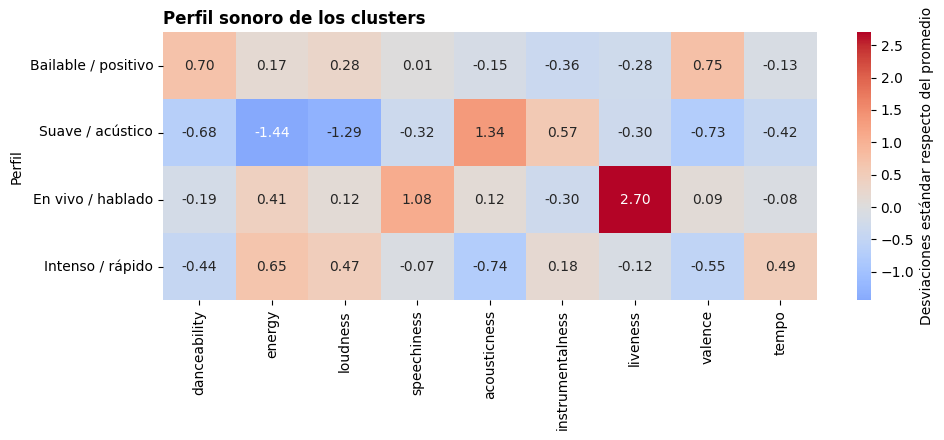

cluster
0               [reggaeton, latino, salsa]
1            [ambient, new-age, classical]
2                  [comedy, pagode, samba]
3    [death-metal, grindcore, black-metal]
Name: track_genres, dtype: object

In [44]:

# Géneros más frecuentes de cada cluster.
# Se usan únicamente para interpretar grupos ya construidos.
generos_top = (
    BD_cluster
    .explode("track_genres")
    .groupby("cluster")["track_genres"]
    .agg(lambda s: s.value_counts().head(3).index.tolist())
)

RES["generos_cluster"] = {
    int(k): v
    for k, v in generos_top.items()
}

# Los centroides están expresados en desviaciones estándar respecto
# del promedio del catálogo, porque K-Means utilizó variables escaladas.
centroides = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=columnas_cluster,
    index=[nombres_clusters[i] for i in range(K)]
)

plt.figure(figsize=(10, 4.5))

sns.heatmap(
    centroides.round(2),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    cbar_kws={"label": "Desviaciones estándar respecto del promedio"}
)

plt.title(
    "Perfil sonoro de los clusters",
    loc="left",
    fontweight="bold"
)
plt.xlabel("")
plt.ylabel("Perfil")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "14_centroides.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

generos_top

**Interpretación de los perfiles:** los centroides muestran que K-Means encontró combinaciones distintas de características sonoras. Los géneros más frecuentes se consultan posteriormente únicamente como apoyo para comprender qué tipos de canciones aparecen en cada grupo; no participaron en la formación de los clusters.

Los nombres **Bailable / positivo**, **Suave / acústico**, **En vivo / hablado** e **Intenso / rápido** son etiquetas descriptivas asignadas después de revisar las características promedio de cada cluster. No son categorías oficiales de Spotify ni nombres generados por K-Means.

Los perfiles obtenidos pueden resumirse como:

- **Cluster 0 — Bailable / positivo:** mayor presencia relativa de `danceability` y `valence`.
- **Cluster 1 — Suave / acústico:** mayor `acousticness` y menor intensidad sonora.
- **Cluster 2 — En vivo / hablado:** destaca principalmente por valores elevados de `liveness` y `speechiness`.
- **Cluster 3 — Intenso / rápido:** mayor energía y tempo, junto con menor `acousticness`.

La popularidad media y mediana son relativamente similares entre los perfiles. Por tanto, **la segmentación sonora no separa fuertemente a las canciones según `popularity`**.

Esto complementa el análisis supervisado: las características de audio contienen información suficiente para describir distintos perfiles sonoros, aunque por sí solas aportan poco para estimar la popularidad.

### 11.5 PCA y visualización


Varianza explicada PC1 y PC2: [0.32 0.16] | total: 0.48


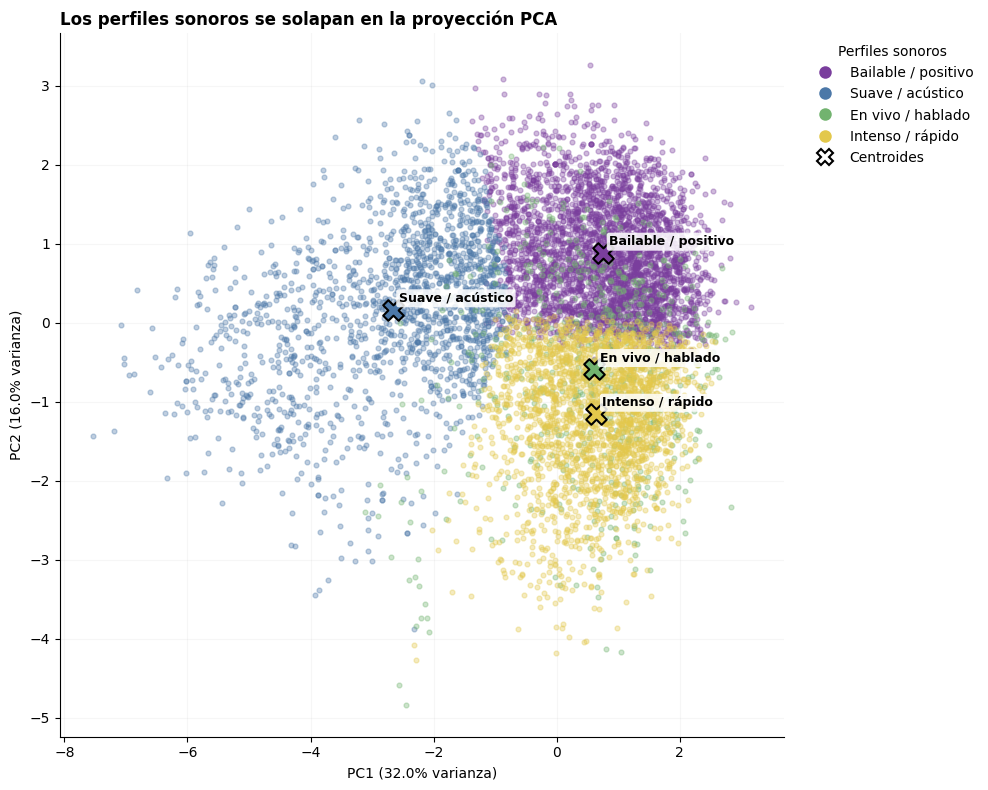

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.26,0.51,0.52,0.10,-0.43,-0.28,0.09,0.30,0.19
PC2,0.56,-0.28,-0.08,0.04,0.31,-0.31,-0.22,0.52,-0.29


In [45]:
from matplotlib.lines import Line2D

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster_sc)

RES["pca_var"] = [float(v) for v in pca.explained_variance_ratio_]
var_total = pca.explained_variance_ratio_.sum()

print(
    "Varianza explicada PC1 y PC2:",
    pca.explained_variance_ratio_.round(3),
    "| total:",
    round(var_total, 3)
)

# Muestra reproducible para mantener el gráfico legible
idx = np.random.RandomState(RANDOM_STATE).choice(
    len(BD_cluster),
    8000,
    replace=False
)

centros_pca = pca.transform(kmeans.cluster_centers_)

# Colores manuales más distinguibles
colores_clusters = {
    0: "#7A3E9D",  # morado
    1: "#4C78A8",  # azul
    2: "#72B36F",  # verde
    3: "#E3C84B"   # amarillo
}

fig, ax = plt.subplots(figsize=(10, 8))

clusters_muestra = BD_cluster["cluster"].to_numpy()[idx]

# Dibujar cada cluster por separado
for c in sorted(np.unique(clusters_muestra)):
    mask = clusters_muestra == c

    ax.scatter(
        X_pca[idx, 0][mask],
        X_pca[idx, 1][mask],
        s=12,
        alpha=0.35,
        color=colores_clusters[c],
        rasterized=True
    )

# Centroides: X del mismo color del cluster con borde negro
for i, (x, y) in enumerate(centros_pca):
    ax.scatter(
        x,
        y,
        marker="X",
        s=220,
        color=colores_clusters[i],
        edgecolor="black",
        linewidth=1.5,
        zorder=6
    )

# Posición de las etiquetas de centroides
offsets = {
    0: (0.10, 0.10),
    1: (0.10, 0.10),
    2: (0.10, 0.10),
    3: (0.10, 0.10)
}

for i, (x, y) in enumerate(centros_pca):
    dx, dy = offsets[i]

    ax.text(
        x + dx,
        y + dy,
        nombres_clusters[i],
        fontsize=9,
        fontweight="bold",
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        ),
        zorder=7
    )

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% varianza)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% varianza)"
)

ax.set_title(
    "Los perfiles sonoros se solapan en la proyección PCA",
    loc="left",
    fontweight="bold"
)

# Leyenda manual:
# marcadores más grandes y opacos para que los colores se distingan bien
leyenda = []

for c in sorted(nombres_clusters):
    leyenda.append(
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markerfacecolor=colores_clusters[c],
            markeredgecolor="none",
            markersize=9,
            label=nombres_clusters[c]
        )
    )

leyenda.append(
    Line2D(
        [0], [0],
        marker="X",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=1.5,
        markersize=11,
        label="Centroides"
    )
)

ax.legend(
    handles=leyenda,
    title="Perfiles sonoros",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.grid(alpha=0.10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "15_clusters_pca.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Cargas de los dos componentes principales
cargas_pca = pd.DataFrame(
    pca.components_,
    columns=columnas_cluster,
    index=["PC1", "PC2"]
).round(2)

cargas_pca

In [46]:
conteo_clusters = (
    BD_cluster["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("cantidad")
)

conteo_clusters["porcentaje"] = (
    conteo_clusters["cantidad"] / len(BD_cluster) * 100
).round(2)

conteo_clusters

,cantidad,porcentaje
cluster,,
0,36819,41.03
1,18601,20.73
2,7003,7.80
3,27317,30.44


**Interpretación del PCA:** los dos primeros componentes principales explican aproximadamente el **48% de la variabilidad total**, por lo que la proyección permite observar una parte importante de la estructura de los datos, aunque no la representa completamente.

**PC1** separa principalmente canciones más **energéticas y fuertes** de aquellas más **acústicas e instrumentales**. **PC2** diferencia principalmente según `danceability` y `valence`, junto con aportes opuestos de instrumentalidad, tempo y energía.

La distribución de los clusters muestra una estructura clara pero no completamente separada. **Suave / acústico** se distingue especialmente hacia la izquierda, mientras que **Bailable / positivo** e **Intenso / rápido** ocupan regiones diferentes principalmente en el eje vertical, aunque presentan zonas de transición y solapamiento.

**En vivo / hablado** aparece menos definido visualmente porque se encuentra entre estos últimos perfiles y, además, es el cluster más pequeño: representa solo **7,8%** de las canciones, frente a **41,0%** de Bailable / positivo, **30,4%** de Intenso / rápido y **20,7%** de Suave / acústico. Por ello, hay menos puntos verdes visibles y gran parte de ellos se superpone con los clusters vecinos.

El **Silhouette cercano a 0,17** indica que, considerando las nueve características originales, muchos registros se encuentran próximos a más de un cluster. Esto es consistente con el PCA: los perfiles presentan una organización reconocible, pero sus fronteras son difusas y existe solapamiento entre ellos.

### 11.6 Conclusión del aprendizaje no supervisado

El análisis no supervisado muestra que las características de audio permiten construir **perfiles sonoros interpretables** dentro del catálogo.

Los clusters presentan una separación limitada y sus niveles de `popularity` son relativamente similares. Por lo tanto, estos perfiles resultan más útiles para **describir la diversidad sonora del catálogo** que para distinguir canciones según su nivel de popularidad.

Este resultado es coherente con el aprendizaje supervisado: las variables de audio aportan poco para estimar `popularity`, pero eso no significa que carezcan de información. En el análisis no supervisado sí permiten identificar combinaciones de características sonoras sin utilizar la variable objetivo.

## 12. Integración y conclusiones


### 12.1 Integración de los resultados

El proyecto avanzó por las etapas de **Comprensión del negocio, Comprensión de los datos, Preparación, Modelado y Evaluación** de CRISP-DM. La etapa de Despliegue queda fuera del alcance de esta evaluación.

En el aprendizaje supervisado, el **Árbol de Decisión** obtiene el mejor desempeño de los dos modelos evaluados: `MAE = 11,16` y `R² = 0,37`, frente a `MAE = 11,83` y `R² = 0,35` de la Regresión Lineal combinada. La mejora del Árbol existe, pero es moderada.

El resultado más importante aparece al comparar la información utilizada. Con audio y estructura solamente, la Regresión Lineal obtiene `MAE = 16,52` y `R² ≈ 0,04`, muy cerca del baseline de `MAE = 17,12`. Al incorporar género, el MAE baja hasta aproximadamente **11,89** y el `R²` sube hasta **0,35**. Agregar las características de audio sobre el género mejora muy poco ese resultado.

Por lo tanto, **la diferencia principal proviene de la información disponible, especialmente del género, y no solamente del cambio de algoritmo**.

El aprendizaje no supervisado aporta una conclusión complementaria. K-Means permite describir el catálogo mediante cuatro perfiles sonoros interpretables, aunque con solapamiento entre ellos (`Silhouette ≈ 0,17`). En la proyección PCA, que representa aproximadamente el **48% de la variabilidad**, el perfil Suave / acústico aparece más diferenciado, mientras que los demás presentan mayor solapamiento.

En conjunto, ambos enfoques muestran que **las características de audio aportan poco para estimar `popularity`, pero sí contienen información útil para describir la estructura sonora del catálogo**.


### 12.2 Alcance para el problema de negocio

El problema original busca apoyar decisiones de promoción y priorización de canciones. Sin embargo, los resultados actuales deben interpretarse dentro de los límites del dataset.

El modelo supervisado estima el valor de `popularity` **observado en el dataset**. No permite afirmar que una canción tendrá determinada popularidad en el futuro, porque no existen fechas ni una separación entre información disponible antes de una decisión y resultados obtenidos después.

Por la misma razón, todavía no es posible comprobar los KPIs de negocio propuestos en la sección 9.3:

- porcentaje de canciones priorizadas que alcanzan el desempeño esperado;
- porcentaje de canciones con buen desempeño que habían sido priorizadas;
- diferencia frente a una selección de referencia.

El dataset no registra qué canciones fueron priorizadas o promocionadas ni cuál fue su resultado posterior. Por ello, **el modelo no debería usarse todavía como una regla automática para decidir qué canciones promocionar**.

El resultado actual sí permite una conclusión útil: existe información en el dataset para estimar parcialmente la `popularity` observada y sabemos qué tipo de información aporta más. El siguiente paso para acercarse a una decisión real de negocio sería registrar información disponible antes de la promoción, la decisión tomada y el desempeño posterior. Con esos datos podrían evaluarse los KPIs definidos y comprobar si una priorización basada en el modelo mejora realmente una selección de referencia.


### 12.3 Consideraciones éticas

`popularity` representa comportamiento de consumo dentro de Spotify y **no una medida de calidad musical**.

El género aporta gran parte de la capacidad de estimación del modelo y, al mismo tiempo, el EDA muestra diferencias importantes de popularidad promedio entre géneros. Esto genera un riesgo: un modelo que utiliza género puede **repetir diferencias que ya están presentes en los datos**.

Con este análisis no se puede concluir que un género cause mayor o menor popularidad, ni que los géneros con menor promedio tengan menor calidad. Tampoco se ha demostrado que el modelo perjudique de forma sistemática a un género específico.

Por ello, cualquier uso futuro del modelo debería mantener esta distinción y evitar utilizar sus resultados como medida de valor cultural o como único criterio para descartar canciones o artistas.


### 12.4 Limitaciones y próximos pasos

Las principales limitaciones del proyecto son:

- `popularity` corresponde a una observación del momento de extracción y no a un resultado futuro.
- En **720 pistas** se observaron valores distintos de `popularity` para un mismo `track_id`; estos casos se consolidaron mediante la mediana y quedaron documentados.
- El mejor modelo alcanza `R² ≈ 0,37`, por lo que una parte importante de la variabilidad de `popularity` permanece sin explicar.
- Los errores son mayores en valores extremos y especialmente en canciones con `popularity = 0`.
- La división aleatoria entre entrenamiento y prueba evalúa otras canciones del mismo conjunto de datos, pero no permite comprobar desempeño en un periodo futuro.
- Los clusters de K-Means presentan solapamiento (`Silhouette ≈ 0,17`) y deben interpretarse como perfiles descriptivos, no como categorías musicales rígidas.
- La visualización PCA utiliza dos componentes que explican aproximadamente el **48% de la variabilidad**, por lo que no representa toda la información de las nueve variables originales.

Para continuar el proyecto, la prioridad debería ser **mejorar la información disponible y la forma de evaluar el problema**, antes de aumentar la complejidad del algoritmo. Sería útil disponer de variables como fecha de lanzamiento, exposición en playlists, información de promoción e historial de audiencia del artista, siempre evaluando después si realmente aportan capacidad de estimación.

Con datos temporales también sería posible separar información disponible antes de una decisión y resultados posteriores, permitiendo evaluar de forma directa los KPIs de negocio definidos en este proyecto. Una vez resuelto ese punto, podrían compararse otros modelos si existe una razón clara para hacerlo.


### 12.5 Guardado de modelos y métricas

Se guardan los modelos y resultados principales para que puedan reutilizarse al ejecutar nuevamente el proyecto. Este guardado **no corresponde a un despliegue del modelo**; solo conserva los objetos generados durante el análisis.


In [47]:

# Guardado de modelos y métricas (carpeta models/)
joblib.dump(
    lineal_completo,
    MODELS_DIR / "regresion_lineal_audio_generos.joblib"
)

joblib.dump(
    arbol_completo,
    MODELS_DIR / "arbol_decision_audio_generos.joblib"
)

joblib.dump(
    {
        "preprocesamiento": prep_cluster,
        "kmeans": kmeans,
        "pca": pca,
        "nombres_clusters": nombres_clusters
    },
    MODELS_DIR / "segmentacion_kmeans_pca.joblib"
)

joblib.dump(
    mlb_generos,
    MODELS_DIR / "codificador_generos.joblib"
)

with open(MODELS_DIR / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2, default=str)

print("Modelos y métricas guardados en:", MODELS_DIR.resolve())


Modelos y métricas guardados en: D:\DUOC\Machine_Learning\Spotify_ML_portable\models
